# Eksplorasi dan Preprocessing Data MVSA-Multiple

Notebook ini mendokumentasikan tahap persiapan data pada penelitian analisis sentimen multimodal berbasis teks dan gambar. Dataset yang digunakan adalah MVSA-Multiple (Niu et al., 2016), yaitu kumpulan pasangan teks dan gambar dari Twitter. Setiap pasangan dilabeli oleh tiga annotator untuk modalitas teks dan modalitas gambar dengan tiga kelas sentimen, yaitu positive, neutral, dan negative.

Alur notebook terdiri dari lima bagian.

| Bagian | Isi |
|--------|-----|
| I | Exploratory Data Analysis pada data mentah |
| II | Preprocessing label, yaitu parsing, majority vote, polaritas gabungan, dan validasi file |
| III | Distribusi data setelah preprocessing |
| IV | Contoh preprocessing teks, preprocessing gambar, dan augmentasi |
| V | Ekspor hasil |

Keluaran utama notebook ini adalah berkas `labelResult_cleaned.csv` dengan kolom `ID`, `text_label`, `image_label`, dan `final_label`. Berkas tersebut menjadi masukan bagi notebook pelatihan model.

Bagian I hanya mengamati data dan tidak mengubahnya. Seluruh perubahan data dilakukan pada Bagian II.

## 0. Konfigurasi

Sel berikut memuat pustaka, menetapkan path dataset, dan mendefinisikan konstanta serta fungsi yang dipakai di seluruh notebook. Nilai seed dikunci agar proses pemilihan sampel dapat direproduksi.

In [1]:
import os, re, random, textwrap, time, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageStat

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **kw: x

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

# ── Path dataset ──────────────────────────────────────────────────────
DATA_DIR   = '/kaggle/input/datasets/vincemarcs/mvsamultiple/MVSA/data'
LABEL_PATH = '/kaggle/input/datasets/vincemarcs/mvsamultiple/MVSA/labelResultAll.txt'

# ── Folder output ─────────────────────────────────────────────────────
OUTPUT_DIR = 'output_mvsa_multiple'
FIG_DIR    = os.path.join(OUTPUT_DIR, 'grafik')
os.makedirs(FIG_DIR, exist_ok=True)

# ── Konstanta bersama ─────────────────────────────────────────────────
SEED         = 42
CLASSES      = ['positive', 'neutral', 'negative']
CLASS_COLORS = {'positive': '#4CAF50', 'neutral': '#2196F3', 'negative': '#F44336'}

LABEL_NORM = {
    'positive': 'positive', 'pos': 'positive',
    'neutral':  'neutral',  'neu': 'neutral',
    'negative': 'negative', 'neg': 'negative',
}

def parse_pair(value):
    """Pecah 'text_label,image_label' menjadi tuple (text, image). None bila format tidak valid."""
    parts = str(value).strip().split(',')
    if len(parts) != 2:
        return (None, None)
    return (LABEL_NORM.get(parts[0].strip().lower()),
            LABEL_NORM.get(parts[1].strip().lower()))

# Jenis noise pada teks tweet
NOISE_PATTERNS = {
    'RT'       : r'\bRT\b\s*@\w+:?\s*',
    'Mention'  : r'@\w+',
    'URL'      : r'http\S+|www\S+',
    'Hashtag'  : r'#\w+',
    'Non-ASCII': r'[^\x00-\x7F]+',
}

def read_text(id_):
    with open(os.path.join(DATA_DIR, f'{id_}.txt'), 'r', encoding='utf-8', errors='ignore') as f:
        return f.read().strip()

def clean_text(text):
    # Sama dengan fungsi pada notebook pelatihan ALBERT
    text = re.sub(r'\bRT\b\s*@\w+:?\s*', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

random.seed(SEED); np.random.seed(SEED)
print('Konfigurasi siap.')

Konfigurasi siap.


# Bagian I. Exploratory Data Analysis pada Data Mentah

Tujuan bagian ini adalah memahami kualitas, struktur, dan karakteristik data sebelum diolah. Hasil eksplorasi menjadi dasar bagi keputusan preprocessing pada Bagian II dan IV. Analisis mencakup kualitas tabel anotasi, distribusi dan kesepakatan label, kelengkapan file, serta karakteristik gambar dan teks.

## 1. Pemuatan Data Anotasi

Berkas `labelResultAll.txt` berisi satu baris untuk setiap pasangan teks dan gambar. Kolom `ID` menjadi kunci terhadap berkas `<ID>.jpg` dan `<ID>.txt`. Tiga kolom lainnya memuat label dari masing-masing annotator dengan format `label_teks,label_gambar`.

In [2]:
raw_df = pd.read_csv(LABEL_PATH, sep='\t')
ann_cols_raw = [c for c in raw_df.columns if c != 'ID']

print(f"Jumlah baris data mentah : {len(raw_df):,}")
print(f"Kolom                    : {list(raw_df.columns)}")
raw_df.head()

Jumlah baris data mentah : 19,600
Kolom                    : ['ID', 'text,image', 'text,image.1', 'text,image.2']


,ID,"text,image","text,image.1","text,image.2"
0,2499,"positive,positive","neutral,neutral","positive,positive"
1,2500,"neutral,positive","positive,positive","neutral,neutral"
2,2501,"negative,negative","neutral,neutral","positive,positive"
3,2502,"positive,positive","positive,positive","positive,positive"
4,2503,"positive,neutral","positive,negative","positive,positive"


## 2. Struktur dan Kualitas Tabel Anotasi

Pemeriksaan awal mencakup tipe data, nilai kosong, duplikasi `ID`, dan validitas format setiap sel anotasi. Daftar nilai label unik digunakan untuk memastikan tidak ada penulisan label di luar tiga kelas yang diharapkan.

In [3]:
# ── Struktur dan kualitas tabel anotasi ──
print('Tipe data tiap kolom')
print(raw_df.dtypes.to_string())

print('\nNilai kosong per kolom')
print(raw_df.isna().sum().to_string())

n_dup_id = int(raw_df['ID'].duplicated().sum())
print(f"\nID duplikat              : {n_dup_id}")

# Validitas format 'text_label,image_label' pada tiap sel anotasi
fmt_invalid = {}
for col in ann_cols_raw:
    parsed = raw_df[col].apply(parse_pair)
    fmt_invalid[col] = int(parsed.apply(lambda x: x[0] is None or x[1] is None).sum())
print('\nSel anotasi dengan format atau label tidak valid')
print(pd.Series(fmt_invalid).to_string())

# Nilai label unik pada seluruh sel anotasi (sebelum normalisasi)
tokens = Counter()
for col in ann_cols_raw:
    for v in raw_df[col].astype(str):
        for t in v.split(','):
            tokens[t.strip().lower()] += 1
print('\nNilai label unik pada seluruh sel anotasi')
print(pd.Series(tokens).sort_values(ascending=False).to_string())

Tipe data tiap kolom
ID               int64
text,image      object
text,image.1    object
text,image.2    object

Nilai kosong per kolom
ID              0
text,image      0
text,image.1    0
text,image.2    0

ID duplikat              : 0

Sel anotasi dengan format atau label tidak valid
text,image      0
text,image.1    0
text,image.2    0

Nilai label unik pada seluruh sel anotasi
positive    58113
neutral     47974
negative    11513


## 3. Distribusi Label Mentah per Annotator

Distribusi label diamati terpisah untuk setiap annotator dan setiap modalitas. Pengamatan ini menunjukkan kecenderungan pelabelan masing-masing annotator serta tingkat ketidakseimbangan kelas pada data mentah. Kolom anotasi dipecah menjadi label teks dan label gambar pada salinan tabel bernama `lab`, sehingga `raw_df` tetap utuh.

Distribusi label mentah per annotator (jumlah dan persentase)
Modalitas Annotator  N valid       positive       neutral      negative
     Teks        A1    19600  9,728 (49.6%) 8,072 (41.2%)  1,800 (9.2%)
     Teks        A2    19600 10,207 (52.1%) 7,606 (38.8%)  1,787 (9.1%)
     Teks        A3    19600  9,367 (47.8%) 8,820 (45.0%)  1,413 (7.2%)
   Gambar        A1    19600  9,801 (50.0%) 7,426 (37.9%) 2,373 (12.1%)
   Gambar        A2    19600  9,798 (50.0%) 7,477 (38.1%) 2,325 (11.9%)
   Gambar        A3    19600  9,212 (47.0%) 8,573 (43.7%)  1,815 (9.3%)


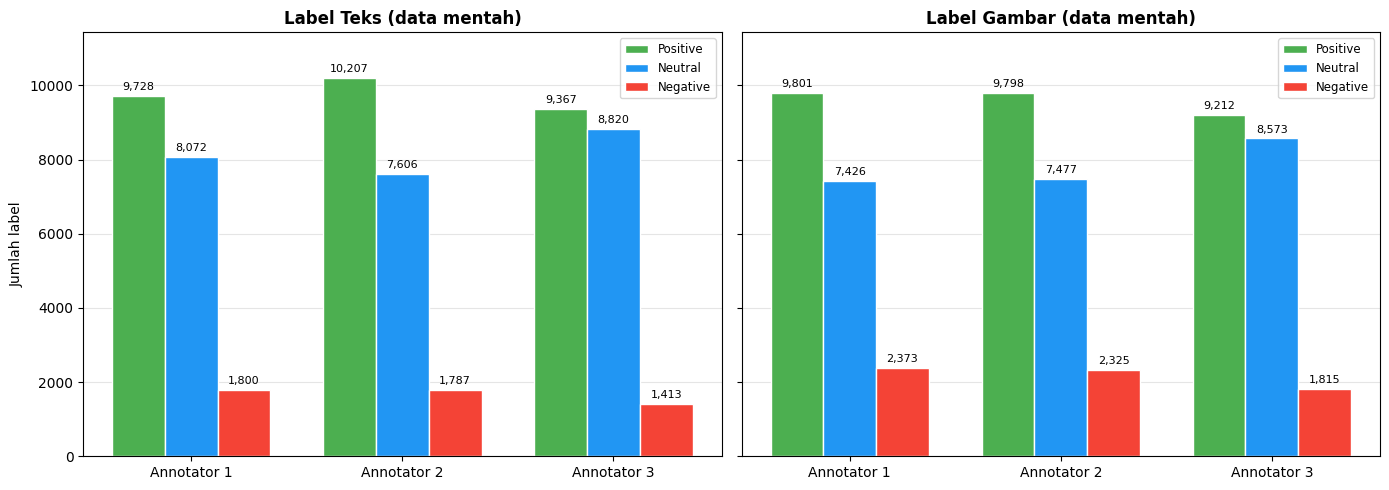

In [4]:
# Salinan label yang sudah dipecah per modalitas. raw_df tidak diubah pada bagian EDA.
lab = pd.DataFrame({'ID': raw_df['ID']})
for k, col in enumerate(ann_cols_raw, start=1):
    pr = raw_df[col].apply(parse_pair)
    lab[f'ann{k}_text']  = pr.str[0]
    lab[f'ann{k}_image'] = pr.str[1]
N_ANN = len(ann_cols_raw)

rows = []
for mod, nama in (('text', 'Teks'), ('image', 'Gambar')):
    for k in range(1, N_ANN + 1):
        vc = lab[f'ann{k}_{mod}'].value_counts()
        n  = int(vc.sum())
        row = {'Modalitas': nama, 'Annotator': f'A{k}', 'N valid': n}
        for c in CLASSES:
            row[c] = f"{int(vc.get(c, 0)):,} ({vc.get(c, 0) / n * 100:.1f}%)"
        rows.append(row)
print('Distribusi label mentah per annotator (jumlah dan persentase)')
print(pd.DataFrame(rows).to_string(index=False))

# Grafik
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
x, w = np.arange(N_ANN), 0.25
ymax = max(int((lab[f'ann{k}_{m}'] == c).sum()) for k in range(1, N_ANN + 1) for m in ('text', 'image') for c in CLASSES)
for ax, (mod, title) in zip(axes, (('text', 'Label Teks (data mentah)'), ('image', 'Label Gambar (data mentah)'))):
    for j, c in enumerate(CLASSES):
        vals = [int((lab[f'ann{k}_{mod}'] == c).sum()) for k in range(1, N_ANN + 1)]
        bars = ax.bar(x + (j - 1) * w, vals, w, color=CLASS_COLORS[c], label=c.capitalize(), edgecolor='white')
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + ymax * 0.01, f'{v:,}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels([f'Annotator {k}' for k in range(1, N_ANN + 1)])
    ax.set_title(title, fontweight='bold'); ax.set_ylim(0, ymax * 1.12)
    ax.yaxis.grid(True, color='#e5e5e5'); ax.set_axisbelow(True); ax.legend(fontsize=8.5)
axes[0].set_ylabel('Jumlah label')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_distribusi_mentah_per_annotator.png'), dpi=300, bbox_inches='tight')
plt.show()

## 4. Kesepakatan Antar Annotator

Kesepakatan diukur dari pola suara tiga annotator pada tiap modalitas. Pola `3-0` berarti ketiga annotator memilih label yang sama. Pola `2-1` berarti dua annotator sepakat, dan pola `1-1-1` berarti tidak ada mayoritas. Tingkat kesepakatan juga dinyatakan dengan Fleiss' kappa (Fleiss, 1971) yang mengoreksi kesepakatan akibat kebetulan, dan diinterpretasikan dengan skala Landis dan Koch (1977).

Data dengan pola `1-1-1` tidak memiliki label mayoritas sehingga tidak dapat dipakai sebagai data berlabel tunggal.

Kesepakatan antar annotator per modalitas
Modalitas     N 3-0 (sepakat penuh) 2-1 (mayoritas) 1-1-1 (tanpa mayoritas) Fleiss' kappa Interpretasi
     Teks 19600       6,627 (33.8%)  11,779 (60.1%)            1,194 (6.1%)         0.191       slight
   Gambar 19600       6,531 (33.3%)  11,629 (59.3%)            1,440 (7.3%)         0.203         fair


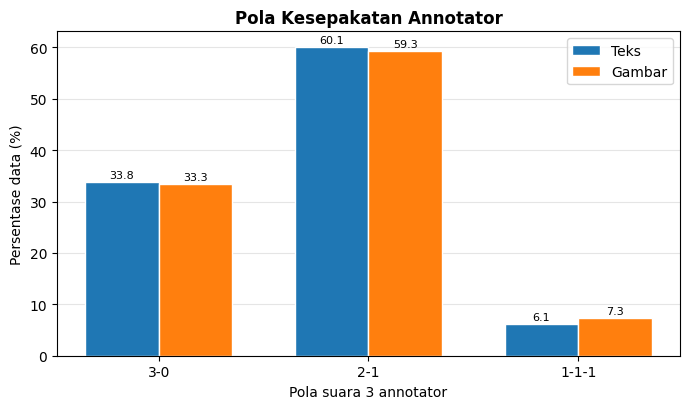

In [5]:
def vote_pattern(labels):
    """Pola suara 3 annotator pada satu modalitas, yaitu '3-0', '2-1', atau '1-1-1'."""
    top = sorted(Counter(labels).values(), reverse=True)
    return {(3,): '3-0', (2, 1): '2-1', (1, 1, 1): '1-1-1'}[tuple(top)]

def fleiss_kappa(mat):
    """Fleiss' kappa. mat berukuran N x k (jumlah suara per kelas), jumlah rater tetap."""
    N, k = mat.shape
    n = mat.sum(axis=1)[0]
    p_j = mat.sum(axis=0) / (N * n)
    P_i = ((mat ** 2).sum(axis=1) - n) / (n * (n - 1))
    P_bar, P_e = P_i.mean(), (p_j ** 2).sum()
    return (P_bar - P_e) / (1 - P_e)

def kappa_scale(k):
    # Skala interpretasi Landis dan Koch (1977)
    if k < 0:    return 'poor'
    if k <= .20: return 'slight'
    if k <= .40: return 'fair'
    if k <= .60: return 'moderate'
    if k <= .80: return 'substantial'
    return 'almost perfect'

PATTERNS = ['3-0', '2-1', '1-1-1']
agree_rows, pattern_counts = [], {}
for mod, nama in (('text', 'Teks'), ('image', 'Gambar')):
    cols = [f'ann{k}_{mod}' for k in range(1, N_ANN + 1)]
    sub  = lab.dropna(subset=cols)
    pats = sub[cols].apply(lambda r: vote_pattern(list(r)), axis=1)
    cnt  = pats.value_counts().reindex(PATTERNS).fillna(0).astype(int)
    pattern_counts[nama] = cnt
    mat   = np.stack([(sub[cols] == c).sum(axis=1).values for c in CLASSES], axis=1)
    kappa = fleiss_kappa(mat)
    agree_rows.append({
        'Modalitas': nama, 'N': len(sub),
        '3-0 (sepakat penuh)': f"{cnt['3-0']:,} ({cnt['3-0'] / len(sub) * 100:.1f}%)",
        '2-1 (mayoritas)'    : f"{cnt['2-1']:,} ({cnt['2-1'] / len(sub) * 100:.1f}%)",
        '1-1-1 (tanpa mayoritas)': f"{cnt['1-1-1']:,} ({cnt['1-1-1'] / len(sub) * 100:.1f}%)",
        "Fleiss' kappa": f'{kappa:.3f}', 'Interpretasi': kappa_scale(kappa),
    })
print('Kesepakatan antar annotator per modalitas')
print(pd.DataFrame(agree_rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.2))
x, w = np.arange(len(PATTERNS)), 0.35
for j, (nama, cnt) in enumerate(pattern_counts.items()):
    pct = cnt.values / cnt.sum() * 100
    bars = ax.bar(x + (j - 0.5) * w, pct, w, label=nama, edgecolor='white')
    for b, v in zip(bars, pct):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(PATTERNS)
ax.set_xlabel('Pola suara 3 annotator'); ax.set_ylabel('Persentase data (%)')
ax.set_title('Pola Kesepakatan Annotator', fontweight='bold')
ax.yaxis.grid(True, color='#e5e5e5'); ax.set_axisbelow(True); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_pola_kesepakatan.png'), dpi=300, bbox_inches='tight')
plt.show()

## 5. Hubungan Label Teks dan Label Gambar

Pada data multimodal, label teks dan label gambar dapat bertentangan. Analisis ini menghitung kombinasi label teks dan gambar dari seluruh annotator. Proporsi konflik polar, yaitu teks positif dengan gambar negatif atau sebaliknya, menentukan perlunya aturan penggabungan label pada Bagian II.

Jumlah pasangan label (seluruh annotator): 58,800

Jumlah (baris = label teks, kolom = label gambar)
image     positive  neutral  negative
text                                 
positive     22704     5384      1214
neutral       5496    16934      2068
negative       611     1158      3231

Persentase terhadap seluruh pasangan (%)
image     positive  neutral  negative
text                                 
positive     38.61     9.16      2.06
neutral       9.35    28.80      3.52
negative      1.04     1.97      5.49

Label teks sama dengan label gambar : 72.91%
Salah satu netral                   : 23.99%
Konflik polar (positif vs negatif)  : 3.10%


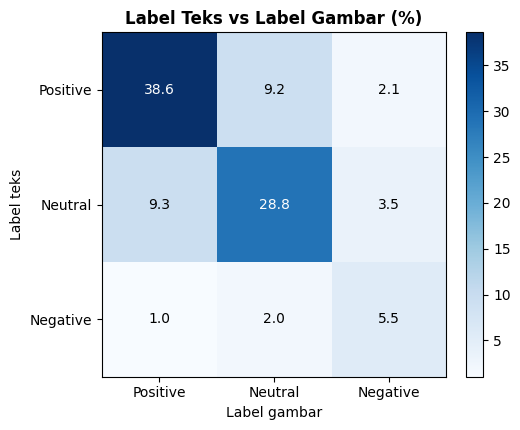

In [6]:
# Pasangan label teks dan gambar dari seluruh annotator (tiap annotator dihitung satu kali)
pairs = pd.concat([
    lab[[f'ann{k}_text', f'ann{k}_image']].set_axis(['text', 'image'], axis=1)
    for k in range(1, N_ANN + 1)
]).dropna()

ct   = pd.crosstab(pairs['text'], pairs['image']).reindex(index=CLASSES, columns=CLASSES).fillna(0).astype(int)
ct_p = (ct / ct.values.sum() * 100).round(2)

print(f'Jumlah pasangan label (seluruh annotator): {len(pairs):,}')
print('\nJumlah (baris = label teks, kolom = label gambar)')
print(ct.to_string())
print('\nPersentase terhadap seluruh pasangan (%)')
print(ct_p.to_string())

same     = int(np.trace(ct.values))
conflict = int(ct.loc['positive', 'negative'] + ct.loc['negative', 'positive'])
print(f"\nLabel teks sama dengan label gambar : {same / ct.values.sum() * 100:.2f}%")
print(f"Salah satu netral                   : {(ct.values.sum() - same - conflict) / ct.values.sum() * 100:.2f}%")
print(f"Konflik polar (positif vs negatif)  : {conflict / ct.values.sum() * 100:.2f}%")

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(ct_p.values, cmap='Blues')
ax.set_xticks(range(3)); ax.set_xticklabels([c.capitalize() for c in CLASSES])
ax.set_yticks(range(3)); ax.set_yticklabels([c.capitalize() for c in CLASSES])
ax.set_xlabel('Label gambar'); ax.set_ylabel('Label teks')
ax.set_title('Label Teks vs Label Gambar (%)', fontweight='bold')
for i in range(3):
    for j in range(3):
        v = ct_p.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', color='white' if v > ct_p.values.max() * 0.55 else 'black')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_label_teks_vs_gambar.png'), dpi=300, bbox_inches='tight')
plt.show()

## 6. Audit Kelengkapan File

Setiap `ID` pada berkas anotasi harus memiliki pasangan berkas gambar dan teks. Audit membandingkan daftar `ID` pada anotasi dengan isi folder data, termasuk berkas yang tidak memiliki anotasi.

In [7]:
# ── Audit kelengkapan file ──
files    = os.listdir(DATA_DIR)
jpg_ids  = {f[:-4] for f in files if f.lower().endswith('.jpg')}
txt_ids  = {f[:-4] for f in files if f.lower().endswith('.txt')}
other    = [f for f in files if not f.lower().endswith(('.jpg', '.txt'))]
label_ids = set(raw_df['ID'].astype(str))

audit = {
    'ID pada file anotasi'            : len(label_ids),
    'File .jpg pada folder data'      : len(jpg_ids),
    'File .txt pada folder data'      : len(txt_ids),
    'File dengan ekstensi lain'       : len(other),
    'ID anotasi tanpa file .jpg'      : len(label_ids - jpg_ids),
    'ID anotasi tanpa file .txt'      : len(label_ids - txt_ids),
    'File .jpg tanpa ID anotasi'      : len(jpg_ids - label_ids),
    'File .txt tanpa ID anotasi'      : len(txt_ids - label_ids),
}
print(pd.Series(audit).to_string())

ID pada file anotasi          19600
File .jpg pada folder data    19600
File .txt pada folder data    19600
File dengan ekstensi lain         0
ID anotasi tanpa file .jpg        0
ID anotasi tanpa file .txt        0
File .jpg tanpa ID anotasi        0
File .txt tanpa ID anotasi        0


## 7. Pemindaian Gambar dan Teks

Seluruh `ID` dipindai satu kali untuk memperoleh dimensi gambar, format gambar, isi teks, panjang teks, dan keberadaan noise. Pemindaian memakai thread karena proses ini dibatasi oleh kecepatan baca berkas. Hasilnya disimpan pada tabel `meta_raw` dan dipakai oleh dua bagian berikutnya.

In [8]:
# ── Pemindaian gambar dan teks untuk seluruh ID anotasi ──
# Gambar hanya dibuka untuk membaca dimensi (tanpa decode penuh), sehingga pemindaian cepat.
def scan_one(id_):
    out = {'ID': id_, 'img_exists': False, 'txt_exists': False, 'img_ok': False,
           'width': np.nan, 'height': np.nan, 'img_format': None, 'img_mode': None,
           'text': '', 'n_chars': 0, 'n_words': 0, 'n_words_clean': 0}
    for k in NOISE_PATTERNS:
        out[f'noise_{k}'] = False

    ip = os.path.join(DATA_DIR, f'{id_}.jpg')
    tp = os.path.join(DATA_DIR, f'{id_}.txt')
    out['img_exists'], out['txt_exists'] = os.path.exists(ip), os.path.exists(tp)

    if out['img_exists']:
        try:
            with Image.open(ip) as im:
                out['width'], out['height'] = im.size
                out['img_format'], out['img_mode'] = im.format, im.mode
            out['img_ok'] = True
        except Exception:
            pass
    if out['txt_exists']:
        with open(tp, 'r', encoding='utf-8', errors='ignore') as f:
            t = f.read().strip()
        out['text'], out['n_chars'], out['n_words'] = t, len(t), len(t.split())
        out['n_words_clean'] = len(clean_text(t).split())
        for k, p in NOISE_PATTERNS.items():
            out[f'noise_{k}'] = bool(re.search(p, t))
    return out

t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    meta_raw = pd.DataFrame(list(tqdm(ex.map(scan_one, raw_df['ID'].tolist()),
                                      total=len(raw_df), desc='Pemindaian')))
print(f'Pemindaian selesai dalam {time.time() - t0:.1f} detik')

print(f"\nGambar tidak ditemukan : {int((~meta_raw['img_exists']).sum())}")
print(f"Gambar gagal dibuka    : {int((meta_raw['img_exists'] & ~meta_raw['img_ok']).sum())}")
print(f"Teks tidak ditemukan   : {int((~meta_raw['txt_exists']).sum())}")
print(f"Teks kosong            : {int((meta_raw['txt_exists'] & (meta_raw['n_chars'] == 0)).sum())}")

Pemindaian:   0%|          | 0/19600 [00:00<?, ?it/s]

Pemindaian selesai dalam 299.9 detik

Gambar tidak ditemukan : 0
Gambar gagal dibuka    : 3
Teks tidak ditemukan   : 0
Teks kosong            : 0


## 8. Karakteristik Gambar

Dimensi gambar menentukan strategi resize. Model gambar pada penelitian ini menerima masukan persegi, yaitu 224x224 untuk MobileNetV3-Small dan 256x256 untuk MobileViT-XXS. Gambar dengan rasio lebar terhadap tinggi yang ekstrem akan mengalami distorsi saat diubah ke bentuk persegi, dan gambar yang sangat kecil akan diperbesar sehingga kehilangan ketajaman.

Jumlah gambar yang dianalisis: 19,597

Statistik dimensi gambar
          width    height    aspect  min_side
count  19597.00  19597.00  19597.00  19597.00
mean     576.15    558.92      1.21    478.29
std       71.13    224.33      0.56    126.06
min       69.00     29.00      0.24     29.00
25%      599.00    398.00      0.75    393.00
50%      600.00    523.00      1.02    484.00
75%      600.00    775.00      1.49    600.00
max      600.00   1200.00     11.07    600.00

Format file
img_format
JPEG    19597

Mode warna
img_mode
RGB    19597

Sisi terpendek < 224 piksel   : 3.45%
Sisi terpendek < 256 piksel   : 5.15%
Rasio lebar/tinggi di luar 0,67 sampai 1,5 : 33.35%


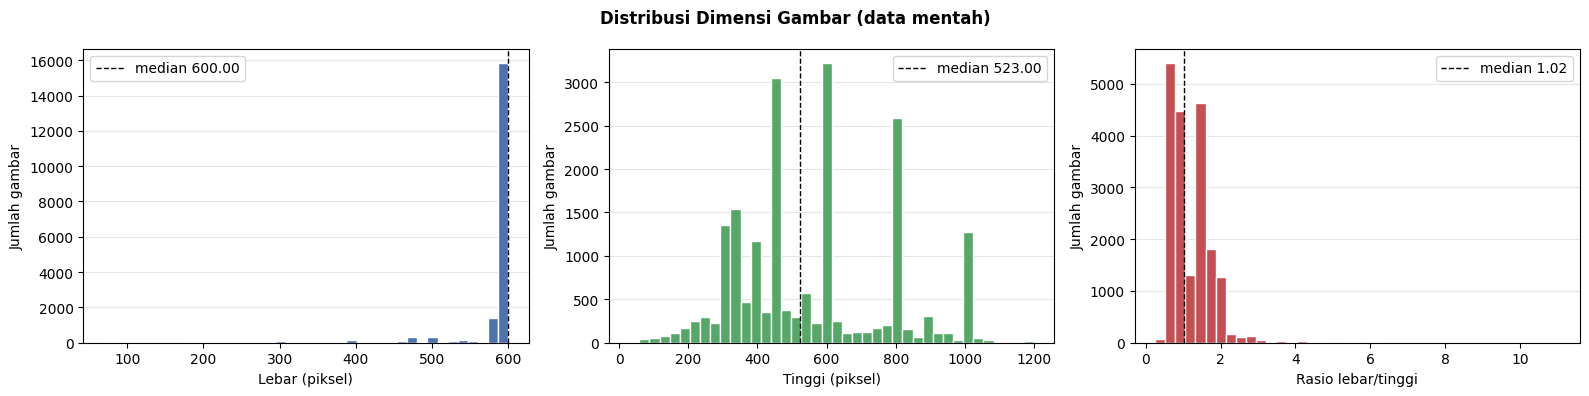

In [9]:
img = meta_raw[meta_raw['img_ok']].copy()
img['aspect']   = img['width'] / img['height']
img['min_side'] = img[['width', 'height']].min(axis=1)

print(f'Jumlah gambar yang dianalisis: {len(img):,}')
print('\nStatistik dimensi gambar')
print(img[['width', 'height', 'aspect', 'min_side']].describe().round(2).to_string())

print('\nFormat file')
print(img['img_format'].value_counts().to_string())
print('\nMode warna')
print(img['img_mode'].value_counts().to_string())

print(f"\nSisi terpendek < 224 piksel   : {(img['min_side'] < 224).mean() * 100:.2f}%")
print(f"Sisi terpendek < 256 piksel   : {(img['min_side'] < 256).mean() * 100:.2f}%")
print(f"Rasio lebar/tinggi di luar 0,67 sampai 1,5 : {((img['aspect'] < 0.67) | (img['aspect'] > 1.5)).mean() * 100:.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, title, color) in zip(axes, (('width', 'Lebar (piksel)', '#4C72B0'),
                                         ('height', 'Tinggi (piksel)', '#55A868'),
                                         ('aspect', 'Rasio lebar/tinggi', '#C44E52'))):
    ax.hist(img[col], bins=40, color=color, edgecolor='white')
    ax.axvline(img[col].median(), color='black', ls='--', lw=1, label=f'median {img[col].median():.2f}')
    ax.set_xlabel(title); ax.set_ylabel('Jumlah gambar'); ax.legend()
    ax.yaxis.grid(True, color='#e5e5e5'); ax.set_axisbelow(True)
fig.suptitle('Distribusi Dimensi Gambar (data mentah)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_dimensi_gambar.png'), dpi=300, bbox_inches='tight')
plt.show()

## 9. Karakteristik Teks

Panjang teks menentukan nilai `max_length` pada tokenizer. Teks tweet juga memuat noise khas media sosial, yaitu penanda retweet (RT), mention, URL, hashtag, dan karakter non-ASCII. Prevalensi tiap jenis noise menjadi dasar pemilihan langkah pembersihan pada fungsi `clean_text`. Jumlah teks yang menjadi kosong setelah pembersihan perlu diketahui karena teks tersebut harus dikeluarkan dari data.

Jumlah teks yang dianalisis: 19,600

Statistik panjang teks
        n_chars   n_words  n_words_clean
count  19600.00  19600.00       19600.00
mean      87.51     12.30          11.52
std       28.65      4.56           4.58
min        2.00      1.00           1.00
25%       67.00      9.00           8.00
50%       97.00     13.00          12.00
75%      112.00     16.00          15.00
max      144.00     27.00          27.00

Teks kosong setelah clean_text : 0
Teks dengan lebih dari 64 kata : 0.00%

Persentase teks yang memuat tiap jenis noise
RT            0.34
Mention      41.45
URL          21.44
Hashtag      93.90
Non-ASCII     2.21
Teks dengan minimal satu jenis noise : 96.53%


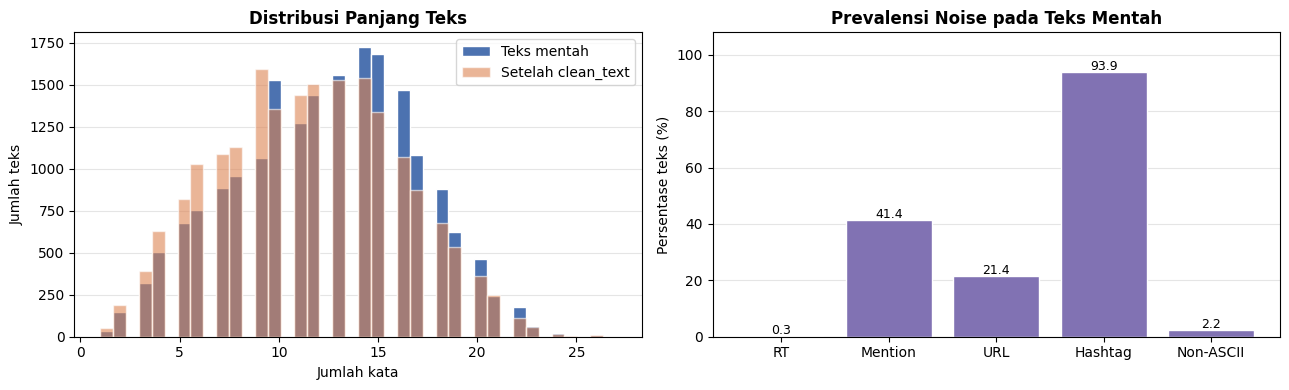

In [10]:
txt = meta_raw[meta_raw['txt_exists']].copy()

print(f'Jumlah teks yang dianalisis: {len(txt):,}')
print('\nStatistik panjang teks')
print(txt[['n_chars', 'n_words', 'n_words_clean']].describe().round(2).to_string())

print(f"\nTeks kosong setelah clean_text : {int((txt['n_words_clean'] == 0).sum())}")
print(f"Teks dengan lebih dari 64 kata : {(txt['n_words'] > 64).mean() * 100:.2f}%")

# Prevalensi noise pada teks mentah
noise_cols = [f'noise_{k}' for k in NOISE_PATTERNS]
prev = (txt[noise_cols].mean() * 100).rename(lambda c: c.replace('noise_', ''))
print('\nPersentase teks yang memuat tiap jenis noise')
print(prev.round(2).to_string())
print(f"Teks dengan minimal satu jenis noise : {(txt[noise_cols].any(axis=1)).mean() * 100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(txt['n_words'], bins=40, color='#4C72B0', edgecolor='white', label='Teks mentah')
axes[0].hist(txt['n_words_clean'], bins=40, color='#DD8452', alpha=0.6, edgecolor='white', label='Setelah clean_text')
axes[0].set_xlabel('Jumlah kata'); axes[0].set_ylabel('Jumlah teks')
axes[0].set_title('Distribusi Panjang Teks', fontweight='bold'); axes[0].legend()
axes[0].yaxis.grid(True, color='#e5e5e5'); axes[0].set_axisbelow(True)

bars = axes[1].bar(prev.index, prev.values, color='#8172B3', edgecolor='white')
for b, v in zip(bars, prev.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}', ha='center', fontsize=9)
axes[1].set_ylabel('Persentase teks (%)'); axes[1].set_ylim(0, max(prev.max() * 1.15, 5))
axes[1].set_title('Prevalensi Noise pada Teks Mentah', fontweight='bold')
axes[1].yaxis.grid(True, color='#e5e5e5'); axes[1].set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_karakteristik_teks.png'), dpi=300, bbox_inches='tight')
plt.show()

## 10. Contoh Data Mentah

Pengamatan visual terhadap sampel acak melengkapi analisis kuantitatif. Sampel diambil dengan seed tetap dari data yang gambarnya terbaca dan teksnya tidak kosong. Notasi label menggunakan tiga huruf pertama dari label tiap annotator.

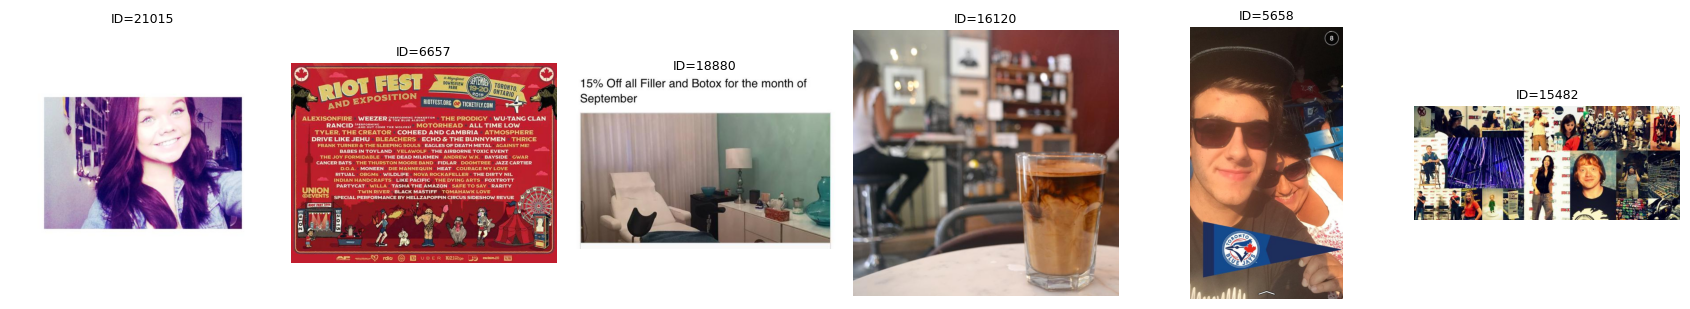

ID=21015 | Teks pos/neu/neu | Gambar pos/neu/pos
    #SelfieForNash @Nashgrier Hi Nash?? I love you very much??
ID=6657 | Teks pos/pos/pos | Gambar pos/pos/neu
    @RiotFest and Exposition will be rocking @downsviewpark Sept 19th &amp; 20th. #Toronto #music #concert
ID=18880 | Teks neu/pos/neu | Gambar neu/pos/neu
    For the month of #september we offering 15% off #Botox and #filler visit book now #yycwoman
    http://t.co/1Tp5eHz1FD
ID=16120 | Teks neu/pos/neu | Gambar neu/neu/pos
    Wednesday is the new Thursday is the new Friday #humpday #torontocoffee #americano #coffeehouse #coffee
ID=5658 | Teks neu/pos/pos | Gambar neu/pos/neu
    Go @BlueJays Go!!!!! #BlueJays #ComeTogether
ID=15482 | Teks neu/neu/neu | Gambar pos/neu/pos
    #FanExpoCAN is on for one more day, #Toronto! Here's what you've missed so far this weekend!
    http://t.co/NBs5IezBmu


In [11]:
# Contoh acak data mentah (seed tetap)
ok_ids = meta_raw.loc[meta_raw['img_ok'] & (meta_raw['n_chars'] > 0), 'ID']
sample_ids = ok_ids.sample(6, random_state=SEED).tolist()
lab_idx = lab.set_index('ID')

fig, axes = plt.subplots(1, 6, figsize=(17, 3.2))
for ax, id_ in zip(axes, sample_ids):
    ax.axis('off')
    with Image.open(os.path.join(DATA_DIR, f'{id_}.jpg')) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(f'ID={id_}', fontsize=9)
plt.tight_layout(); plt.show()

for id_ in sample_ids:
    r = lab_idx.loc[id_]
    t = '/'.join(str(r[f'ann{k}_text'])[:3] for k in range(1, N_ANN + 1))
    i = '/'.join(str(r[f'ann{k}_image'])[:3] for k in range(1, N_ANN + 1))
    print(f'ID={id_} | Teks {t} | Gambar {i}')
    print(textwrap.fill(read_text(id_).replace('\n', ' '), width=110, initial_indent='    ', subsequent_indent='    '))

## 11. Ringkasan Temuan EDA

Tabel berikut merangkum temuan utama. Temuan ini menjadi dasar keputusan pada Bagian II dan IV.
- Data tanpa mayoritas dikeluarkan melalui majority vote.
- Konflik polar antara label teks dan gambar diselesaikan melalui aturan polaritas.
- Pasangan file yang tidak lengkap, gambar yang tidak terbaca, dan teks kosong dikeluarkan melalui validasi file.
- Noise pada teks dibersihkan dengan `clean_text`.
- Gambar diseragamkan melalui resize dan normalisasi.

In [12]:
img_ok_n = int(meta_raw['img_ok'].sum())
rep = {
    'Jumlah baris anotasi'                       : f"{len(raw_df):,}",
    'ID duplikat'                                : n_dup_id,
    'Sel anotasi dengan format tidak valid'      : sum(fmt_invalid.values()),
    'Data tanpa mayoritas pada teks'             : f"{pattern_counts['Teks']['1-1-1']:,}",
    'Data tanpa mayoritas pada gambar'           : f"{pattern_counts['Gambar']['1-1-1']:,}",
    'Pasangan label teks dan gambar berkonflik polar (%)': f"{conflict / ct.values.sum() * 100:.2f}",
    'ID anotasi tanpa pasangan file lengkap'     : int((~(meta_raw['img_exists'] & meta_raw['txt_exists'])).sum()),
    'Gambar gagal dibuka'                        : int((meta_raw['img_exists'] & ~meta_raw['img_ok']).sum()),
    'Teks kosong'                                : int((meta_raw['txt_exists'] & (meta_raw['n_chars'] == 0)).sum()),
    'Teks dengan minimal satu jenis noise (%)'   : f"{(meta_raw.loc[meta_raw['txt_exists'], noise_cols].any(axis=1)).mean() * 100:.2f}",
    'Gambar dengan sisi terpendek < 224 (%)'     : f"{(img['min_side'] < 224).mean() * 100:.2f}",
}
print(pd.Series(rep).to_string())

Jumlah baris anotasi                                   19,600
ID duplikat                                                 0
Sel anotasi dengan format tidak valid                       0
Data tanpa mayoritas pada teks                          1,194
Data tanpa mayoritas pada gambar                        1,440
Pasangan label teks dan gambar berkonflik polar (%)      3.10
ID anotasi tanpa pasangan file lengkap                      0
Gambar gagal dibuka                                         3
Teks kosong                                                 0
Teks dengan minimal satu jenis noise (%)                96.53
Gambar dengan sisi terpendek < 224 (%)                   3.45


# Bagian II. Preprocessing Label dan Validasi File

Bagian ini mengubah data mentah menjadi data bersih dengan satu label sentimen untuk setiap pasangan teks dan gambar. Tahapannya berurutan, yaitu parsing label, majority vote per modalitas, penggabungan polaritas, dan validasi file. Setiap tahap mencatat jumlah data yang dikeluarkan agar alur penyaringan dapat ditelusuri.

## 12. Parsing Label per Annotator

Setiap sel anotasi dengan format `label_teks,label_gambar` dipecah menjadi dua kolom, lalu dinormalisasi ke tiga kelas baku. Sel yang gagal diparsing diberi nilai kosong dan akan dikeluarkan pada tahap majority vote.

In [13]:
# Kolom anotasi (semua kecuali 'ID')
ann_cols = [c for c in raw_df.columns if c != 'ID']
print(f"Kolom anotasi: {ann_cols}")

# Normalisasi label
LABEL_NORM = {
    'positive': 'positive', 'pos': 'positive',
    'neutral':  'neutral',  'neu': 'neutral',
    'negative': 'negative', 'neg': 'negative',
}

def parse_pair(value):
    """Pecah 'text_label,image_label' menjadi tuple (text, image)."""
    parts = str(value).strip().split(',')
    if len(parts) != 2:
        return (None, None)
    t = LABEL_NORM.get(parts[0].strip().lower())
    i = LABEL_NORM.get(parts[1].strip().lower())
    return (t, i)

# Parse semua kolom annotator
for idx, col in enumerate(ann_cols, start=1):
    parsed = raw_df[col].apply(parse_pair)
    raw_df[f'ann{idx}_text']  = parsed.apply(lambda x: x[0])
    raw_df[f'ann{idx}_image'] = parsed.apply(lambda x: x[1])

# Label tidak valid (gagal parsing atau di luar 3 kelas)
parsed_cols = [f'ann{k}_{m}' for k in range(1, len(ann_cols) + 1) for m in ('text', 'image')]
drop_invalid = int(raw_df[parsed_cols].isna().any(axis=1).sum())
print(f"Baris dengan label tidak valid: {drop_invalid}")

print("\nContoh hasil parsing (5 baris pertama):")
raw_df[['ID', 'ann1_text', 'ann1_image', 'ann2_text', 'ann2_image', 'ann3_text', 'ann3_image']].head()

Kolom anotasi: ['text,image', 'text,image.1', 'text,image.2']
Baris dengan label tidak valid: 0

Contoh hasil parsing (5 baris pertama):


,ID,ann1_text,ann1_image,ann2_text,ann2_image,ann3_text,ann3_image
0,2499,positive,positive,neutral,neutral,positive,positive
1,2500,neutral,positive,positive,positive,neutral,neutral
2,2501,negative,negative,neutral,neutral,positive,positive
3,2502,positive,positive,positive,positive,positive,positive
4,2503,positive,neutral,positive,negative,positive,positive


## 13. Majority Vote per Modalitas

Label akhir tiap modalitas adalah label yang dipilih oleh minimal dua dari tiga annotator. Data tanpa kesepakatan dikeluarkan secara bertahap. Modalitas teks diperiksa lebih dulu, lalu modalitas gambar pada data yang tersisa. Jumlah data yang dikeluarkan pada tiap modalitas dicatat terpisah.

In [14]:
VALID_LABELS = {'positive', 'neutral', 'negative'}

def majority_vote(labels):
    """
    Majority vote: kembalikan label jika >= 2 dari 3 annotator sepakat.
    Return None jika tidak ada kesepakatan.
    """
    clean = [l for l in labels if l in VALID_LABELS]
    counts = Counter(clean)
    for label, count in counts.most_common():
        if count >= 2:
            return label
    return None

# Majority vote untuk modalitas TEKS
raw_df['text_label'] = raw_df.apply(
    lambda r: majority_vote([r['ann1_text'], r['ann2_text'], r['ann3_text']]),
    axis=1
)

# Majority vote untuk modalitas GAMBAR
raw_df['image_label'] = raw_df.apply(
    lambda r: majority_vote([r['ann1_image'], r['ann2_image'], r['ann3_image']]),
    axis=1
)

# ── Drop bertahap: teks dulu, lalu gambar pada data yang tersisa ──
mask_text_fail = raw_df['text_label'].isna()
drop_no_majority_text = int(mask_text_fail.sum())
tmp = raw_df[~mask_text_fail]

mask_image_fail = tmp['image_label'].isna()
drop_no_majority_image = int(mask_image_fail.sum())

df = tmp[~mask_image_fail].copy().reset_index(drop=True)

print(f"drop_no_majority_text  : {drop_no_majority_text}")
print(f"drop_no_majority_image : {drop_no_majority_image}")
print(f"\nSetelah majority vote: {len(df)}  (dari {len(raw_df)} data asli)")

drop_no_majority_text  : 1194
drop_no_majority_image : 1037

Setelah majority vote: 17369  (dari 19600 data asli)


## 14. Polaritas Gabungan (`final_label`)

Label teks dan label gambar digabung menjadi satu label sentimen untuk pasangan tersebut. Aturan penggabungan mengikuti pendekatan Xu dan Mao (2017).

| Teks | Gambar | Label akhir |
|------|--------|-------------|
| positive | positive | positive |
| negative | negative | negative |
| neutral | neutral | neutral |
| positive | neutral | positive |
| neutral | positive | positive |
| negative | neutral | negative |
| neutral | negative | negative |
| positive | negative | dibuang |
| negative | positive | dibuang |

Kombinasi positive dengan negative dibuang karena kedua modalitas memberi sinyal yang berlawanan sehingga tidak ada label tunggal yang dapat dipertanggungjawabkan. Tabel `df` dipertahankan utuh, termasuk baris konflik, agar analisis kesesuaian pada section berikutnya masih dapat menghitung konflik tersebut.

In [15]:
def resolve_polarity(text_label, image_label):
    """
    Gabungkan label teks dan gambar:
    - Sama -> ikuti
    - Salah satu netral -> ikuti yang polar
    - Positif vs Negatif -> 'conflict' (akan di-drop)
    """
    if text_label == image_label:
        return text_label
    if text_label == 'neutral':
        return image_label
    if image_label == 'neutral':
        return text_label
    return 'conflict'  # positif vs negatif

# df tetap utuh (termasuk konflik) agar bisa dipakai untuk analisis kesesuaian
df['final_label'] = df.apply(
    lambda r: resolve_polarity(r['text_label'], r['image_label']),
    axis=1
)

drop_polar_conflict = int((df['final_label'] == 'conflict').sum())
print(f"drop_polar_conflict: {drop_polar_conflict}")

df_pol = df[df['final_label'] != 'conflict'].copy().reset_index(drop=True)
print(f"Setelah buang konflik polar: {len(df_pol)}")

drop_polar_conflict: 342
Setelah buang konflik polar: 17027


## 15. Kesesuaian Label Teks dan Gambar setelah Majority Vote

Analisis ini mengulang pengamatan pada Section 5 dengan label hasil majority vote. Hasilnya menunjukkan seberapa besar data yang dipertahankan, yang dikoreksi oleh aturan netral, dan yang dibuang akibat konflik polar. Analisis dilakukan sebelum baris konflik dibuang.

In [16]:
def agreement_type(t, i):
    if t == i:
        return 'Sama'
    if t == 'neutral' or i == 'neutral':
        return 'Salah satu netral'
    return 'Konflik polar'

df['agreement'] = df.apply(lambda r: agreement_type(r['text_label'], r['image_label']), axis=1)

order = ['Sama', 'Salah satu netral', 'Konflik polar']
agree_summary = df['agreement'].value_counts().reindex(order).fillna(0).astype(int).to_frame('Jumlah')
agree_summary['Persentase (%)'] = (agree_summary['Jumlah'] / len(df) * 100).round(2)

print(f"Basis: {len(df)} data setelah majority vote (sebelum drop konflik polar)\n")
print(agree_summary.to_string())

pct_same    = agree_summary.loc['Sama', 'Persentase (%)']
pct_neutral = agree_summary.loc['Salah satu netral', 'Persentase (%)']
pct_conf    = agree_summary.loc['Konflik polar', 'Persentase (%)']
print(f"\nKesesuaian penuh (label identik)            : {pct_same:.2f}%")
print(f"Tidak bertentangan (Sama + Salah satu netral): {pct_same + pct_neutral:.2f}%")
print(f"Bertentangan (Konflik polar)                 : {pct_conf:.2f}%")

# Detail kombinasi label teks dan gambar
print("\nJumlah per kombinasi (baris = teks, kolom = gambar):")
print(pd.crosstab(df['text_label'], df['image_label'], margins=True).to_string())
print("\nPersentase per kombinasi terhadap seluruh data (%):")
print((pd.crosstab(df['text_label'], df['image_label'], normalize='all') * 100).round(2).to_string())

Basis: 17369 data setelah majority vote (sebelum drop konflik polar)

                   Jumlah  Persentase (%)
agreement                                
Sama                12599           72.54
Salah satu netral    4428           25.49
Konflik polar         342            1.97

Kesesuaian penuh (label identik)            : 72.54%
Tidak bertentangan (Sama + Salah satu netral): 98.03%
Bertentangan (Konflik polar)                 : 1.97%

Jumlah per kombinasi (baris = teks, kolom = gambar):
image_label  negative  neutral  positive    All
text_label                                     
negative          606      243       104    953
neutral           450     4408      1955   6813
positive          238     1780      7585   9603
All              1294     6431      9644  17369

Persentase per kombinasi terhadap seluruh data (%):
image_label  negative  neutral  positive
text_label                              
negative         3.49     1.40      0.60
neutral          2.59    25.38     11.26


## 16. Validasi File Pasangan

Setiap `ID` pada data yang tersisa diperiksa. Pasangan dianggap valid bila berkas `<ID>.jpg` dan `<ID>.txt` ada, gambar dapat dibaca secara penuh, dan teks tidak kosong. Berbeda dengan pemindaian pada Section 7, pemeriksaan ini melakukan decode gambar secara penuh agar gambar yang rusak sebagian dapat terdeteksi. Pemeriksaan memakai thread untuk mempercepat proses baca berkas.

In [17]:
def check_pair(id_):
    img_path = os.path.join(DATA_DIR, f'{id_}.jpg')
    txt_path = os.path.join(DATA_DIR, f'{id_}.txt')

    # Cek keberadaan file
    if not (os.path.exists(img_path) and os.path.exists(txt_path)):
        return 'missing'

    # Cek gambar terbaca
    try:
        with Image.open(img_path) as im:
            im.load()
    except Exception:
        return 'corrupt'

    # Cek teks tidak kosong
    with open(txt_path, 'r', encoding='utf-8', errors='ignore') as f:
        if not f.read().strip():
            return 'empty'

    return 'ok'

# ── Validasi file secara paralel (I/O-bound, jadi thread jauh lebih cepat dari apply serial) ──
import time
from concurrent.futures import ThreadPoolExecutor
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **kw: x

ids = df_pol['ID'].tolist()

N_WORKERS = 16
t0 = time.time()
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    df_pol['file_status'] = list(tqdm(ex.map(check_pair, ids), total=len(ids), desc='Validasi file'))
print(f"Validasi paralel selesai dalam {time.time() - t0:.1f}s ({N_WORKERS} thread)")

status = df_pol['file_status'].value_counts()
drop_missing = int(status.get('missing', 0))
drop_corrupt = int(status.get('corrupt', 0))
drop_empty   = int(status.get('empty', 0))
print(f"drop_missing: {drop_missing}")
print(f"drop_corrupt: {drop_corrupt}")
print(f"drop_empty  : {drop_empty}")

df_final = df_pol[df_pol['file_status'] == 'ok'].copy().reset_index(drop=True)
print(f"\nSetelah validasi file: {len(df_final)}")

Validasi file:   0%|          | 0/17027 [00:00<?, ?it/s]

Validasi paralel selesai dalam 83.4s (16 thread)
drop_missing: 0
drop_corrupt: 3
drop_empty  : 0

Setelah validasi file: 17024


## 17. Ringkasan Alur Penyaringan dan Penyimpanan Data Bersih

Ringkasan berikut memuat jumlah data pada setiap tahap. Data bersih akhir disimpan sebagai `labelResult_cleaned.csv`. Berkas ini hanya memuat kolom yang dibutuhkan notebook pelatihan, yaitu `ID`, `text_label`, `image_label`, dan `final_label`.

In [18]:
print('=' * 55)
print('RINGKASAN')
print('=' * 55)
print(f"Data asli (raw)                     : {len(raw_df)}")
print(f"Drop tanpa majority (teks)          : {drop_no_majority_text}")
print(f"Drop tanpa majority (gambar)        : {drop_no_majority_image}")
print(f"Drop konflik polar                  : {drop_polar_conflict}")
print(f"Drop file hilang / rusak / kosong   : {drop_missing} / {drop_corrupt} / {drop_empty}")
print(f"Data bersih akhir                   : {len(df_final)}")
print('=' * 55)

RINGKASAN
Data asli (raw)                     : 19600
Drop tanpa majority (teks)          : 1194
Drop tanpa majority (gambar)        : 1037
Drop konflik polar                  : 342
Drop file hilang / rusak / kosong   : 0 / 3 / 0
Data bersih akhir                   : 17024


In [19]:
# Simpan label bersih. Format sama dengan labelResult_cleaned.csv yang dibaca notebook pelatihan.
cleaned_csv = os.path.join(OUTPUT_DIR, 'labelResult_cleaned.csv')
df_final[['ID', 'text_label', 'image_label', 'final_label']].to_csv(cleaned_csv, index=False)

print(f"Tersimpan : {cleaned_csv}")
print(f"Jumlah baris : {len(df_final):,}")
pd.read_csv(cleaned_csv).head()

Tersimpan : output_mvsa_multiple/labelResult_cleaned.csv
Jumlah baris : 17,024


,ID,text_label,image_label,final_label
0,2499,positive,positive,positive
1,2500,neutral,positive,positive
2,2502,positive,positive,positive
3,2504,positive,neutral,positive
4,2505,positive,neutral,positive


# Bagian III. Distribusi Data setelah Preprocessing

Bagian ini menampilkan kondisi data bersih akhir. Distribusi kelas diamati untuk menilai tingkat ketidakseimbangan yang masih ada setelah penyaringan. Informasi ini menjadi dasar pemilihan fungsi loss pada tahap pelatihan.

## 18. Distribusi Kelas pada Data Akhir

Tabel menunjukkan jumlah dan persentase tiap kelas pada `final_label`, `text_label`, dan `image_label`.

In [20]:
def dist_table(series, title):
    print(f"\n{title}")
    print(f"{'Label':<12} {'Jumlah':>8} {'Persentase':>12}")
    print('-' * 34)
    for label in ['positive', 'neutral', 'negative']:
        count = int((series == label).sum())
        print(f"{label:<12} {count:>8} {count / len(series) * 100:>11.1f}%")
    print('-' * 34)
    print(f"{'TOTAL':<12} {len(series):>8}")

dist_table(df_final['final_label'], 'Distribusi final_label')
dist_table(df_final['text_label'],  'Distribusi text_label')
dist_table(df_final['image_label'], 'Distribusi image_label')


Distribusi final_label
Label          Jumlah   Persentase
----------------------------------
positive        11318        66.5%
neutral          4408        25.9%
negative         1298         7.6%
----------------------------------
TOTAL           17024

Distribusi text_label
Label          Jumlah   Persentase
----------------------------------
positive         9364        55.0%
neutral          6811        40.0%
negative          849         5.0%
----------------------------------
TOTAL           17024

Distribusi image_label
Label          Jumlah   Persentase
----------------------------------
positive         9539        56.0%
neutral          6430        37.8%
negative         1055         6.2%
----------------------------------
TOTAL           17024


## 19. Persebaran Kelas pada Setiap Tahap Penyaringan

Perbandingan persebaran kelas antar tahap menunjukkan apakah proses penyaringan mengubah komposisi kelas. Tahapan yang dibandingkan adalah label mentah (per annotator dan gabungan), majority vote, setelah polaritas, dan data akhir. Karena `final_label` baru terbentuk setelah majority vote, tahap awalnya sudah memuat konflik polar.


Persebaran label Teks per tahap (jumlah dan persentase)
              Mentah A1       Mentah A2      Mentah A3 Mentah gabungan  Majority vote Setelah polarity          Final
positive  9,728 (49.6%)  10,207 (52.1%)  9,367 (47.8%)  29,302 (49.8%)  9,603 (55.3%)    9,365 (55.0%)  9,364 (55.0%)
neutral   8,072 (41.2%)   7,606 (38.8%)  8,820 (45.0%)  24,498 (41.7%)  6,813 (39.2%)    6,813 (40.0%)  6,811 (40.0%)
negative   1,800 (9.2%)    1,787 (9.1%)   1,413 (7.2%)    5,000 (8.5%)     953 (5.5%)       849 (5.0%)     849 (5.0%)
TOTAL            19,600          19,600         19,600          58,800         17,369           17,027         17,024

Persebaran label Gambar per tahap (jumlah dan persentase)
              Mentah A1      Mentah A2      Mentah A3 Mentah gabungan  Majority vote Setelah polarity          Final
positive  9,801 (50.0%)  9,798 (50.0%)  9,212 (47.0%)  28,811 (49.0%)  9,644 (55.5%)    9,540 (56.0%)  9,539 (56.0%)
neutral   7,426 (37.9%)  7,477 (38.1%)  8,573 (43.7%)  23,47

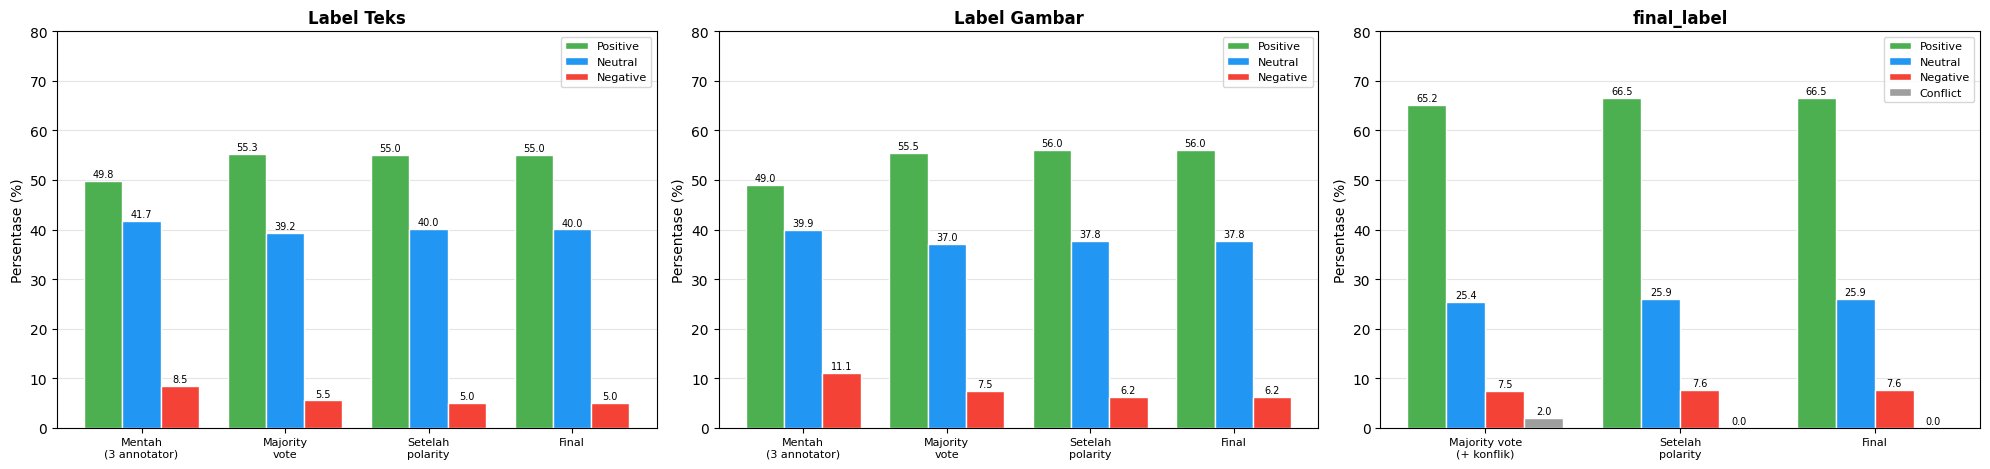

In [21]:
import numpy as np

STAGE_CLASSES = ['positive', 'neutral', 'negative']
STAGE_COLORS  = {'positive': '#4CAF50', 'neutral': '#2196F3', 'negative': '#F44336', 'conflict': '#9E9E9E'}

def stage_table(stages, classes):
    # Jumlah dan persentase tiap kelas pada tiap tahap
    cols = {}
    for name, s in stages.items():
        s = pd.Series(list(s))
        cnt = s.value_counts()
        cols[name.replace('\n', ' ')] = [f"{int(cnt.get(k, 0)):,} ({cnt.get(k, 0) / len(s) * 100:.1f}%)" for k in classes] + [f'{len(s):,}']
    return pd.DataFrame(cols, index=list(classes) + ['TOTAL'])

def plot_stages(ax, stages, classes, title):
    x = np.arange(len(stages))
    w = 0.8 / len(classes)
    for k, c in enumerate(classes):
        vals = [(pd.Series(list(s)) == c).mean() * 100 for s in stages.values()]
        bars = ax.bar(x + (k - (len(classes) - 1) / 2) * w, vals, w, color=STAGE_COLORS[c],
                      label=c.capitalize(), edgecolor='white')
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}', ha='center', fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(list(stages), fontsize=8)
    ax.set_ylabel('Persentase (%)')
    ax.set_title(title, fontweight='bold')
    ax.set_ylim(0, 80)
    ax.yaxis.grid(True, color='#e5e5e5'); ax.set_axisbelow(True)
    ax.legend(fontsize=8)

# ── Label teks dan gambar: mentah (per annotator dan gabungan), majority vote, polarity, final ──
panels = []
for mod, nama in (('text', 'Teks'), ('image', 'Gambar')):
    raw_cols = [raw_df[f'ann{k}_{mod}'] for k in (1, 2, 3)]
    tabel = {
        'Mentah A1': raw_cols[0], 'Mentah A2': raw_cols[1], 'Mentah A3': raw_cols[2],
        'Mentah gabungan': pd.concat(raw_cols),
        'Majority vote': df[f'{mod}_label'],
        'Setelah polarity': df_pol[f'{mod}_label'],
        'Final': df_final[f'{mod}_label'],
    }
    print(f'\nPersebaran label {nama} per tahap (jumlah dan persentase)')
    print(stage_table(tabel, STAGE_CLASSES).to_string())
    panels.append((f'Label {nama}', {'Mentah\n(3 annotator)': tabel['Mentah gabungan'],
                                     'Majority\nvote': tabel['Majority vote'],
                                     'Setelah\npolarity': tabel['Setelah polarity'],
                                     'Final': tabel['Final']}, STAGE_CLASSES))

# ── final_label: baru terbentuk setelah majority vote, konflik polar masih terhitung ──
fl = {'Majority vote\n(+ konflik)': df['final_label'], 'Setelah\npolarity': df_pol['final_label'], 'Final': df_final['final_label']}
print('\nPersebaran final_label per tahap (jumlah dan persentase)')
print(stage_table(fl, STAGE_CLASSES + ['conflict']).to_string())
panels.append(('final_label', fl, STAGE_CLASSES + ['conflict']))

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, (title, stages, classes) in zip(axes, panels):
    plot_stages(ax, stages, classes, title)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'persebaran_per_tahap.png'), dpi=300, bbox_inches='tight')
plt.show()

## 20. Distribusi Sentimen per Modalitas

Grafik membandingkan sebaran kelas label teks dan label gambar pada data akhir. Perbedaan sebaran antar modalitas menunjukkan bahwa kedua modalitas membawa informasi yang tidak identik.

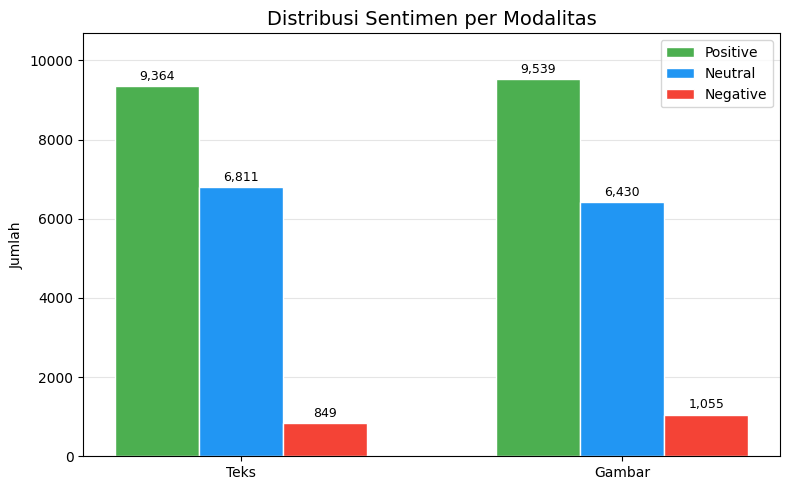

In [22]:
import numpy as np

classes = ['positive', 'neutral', 'negative']
colors  = {'positive': '#4CAF50', 'neutral': '#2196F3', 'negative': '#F44336'}
labels  = {'positive': 'Positive', 'neutral': 'Neutral', 'negative': 'Negative'}

text_counts  = [int((df_final['text_label']  == c).sum()) for c in classes]
image_counts = [int((df_final['image_label'] == c).sum()) for c in classes]

x = np.arange(2)          # 0 = Teks, 1 = Gambar
width = 0.22

fig, ax = plt.subplots(figsize=(8, 5))
for k, c in enumerate(classes):
    vals = [text_counts[k], image_counts[k]]
    bars = ax.bar(x + (k - 1) * width, vals, width, label=labels[c],
                  color=colors[c], edgecolor='white')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + max(text_counts + image_counts) * 0.008,
                f'{v:,}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(['Teks', 'Gambar'])
ax.set_ylabel('Jumlah')
ax.set_title('Distribusi Sentimen per Modalitas', fontsize=14)
ax.set_ylim(0, max(text_counts + image_counts) * 1.12)
ax.yaxis.grid(True, color='#e5e5e5')
ax.set_axisbelow(True)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'distribusi_modalitas.png'), dpi=300, bbox_inches='tight')
plt.show()

## 21. Distribusi Final Label

Grafik menampilkan distribusi `final_label` pada data akhir. Data inilah yang dipakai sebagai target klasifikasi pada tahap pelatihan.

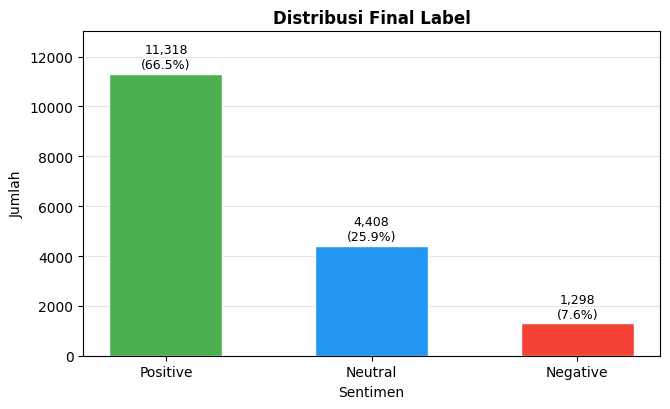

Jumlah sampel: 17,024


In [23]:
# ── Distribusi final_label (data bersih akhir) ──
final_classes = ['positive', 'neutral', 'negative']
final_colors  = ['#4CAF50', '#2196F3', '#F44336']

final_counts = df_final['final_label'].value_counts().reindex(final_classes).fillna(0).astype(int)
ymax = final_counts.max()

fig, ax = plt.subplots(figsize=(6.8, 4.2))
bars = ax.bar([c.capitalize() for c in final_classes], final_counts.values,
              color=final_colors, edgecolor='white', width=0.55)
for bar, val in zip(bars, final_counts.values):
    pct = val / len(df_final) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, val + ymax * 0.01,
            f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Distribusi Final Label', fontweight='bold')
ax.set_xlabel('Sentimen')
ax.set_ylabel('Jumlah')
ax.set_ylim(0, ymax * 1.15)
ax.yaxis.grid(True, color='#e5e5e5')
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'distribusi_final_label.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"Jumlah sampel: {len(df_final):,}")

## 22. Pratinjau Data Akhir

In [24]:
df_final[['ID', 'text_label', 'image_label', 'final_label']].head(10)

,ID,text_label,image_label,final_label
0,2499,positive,positive,positive
1,2500,neutral,positive,positive
2,2502,positive,positive,positive
3,2504,positive,neutral,positive
4,2505,positive,neutral,positive
5,2506,neutral,neutral,neutral
6,2508,negative,neutral,negative
7,2509,negative,negative,negative
8,2510,neutral,neutral,neutral
9,2511,neutral,positive,positive


# Bagian IV. Preprocessing Teks, Gambar, dan Augmentasi

Bagian ini menunjukkan langkah preprocessing yang diterapkan pada masukan model, dengan contoh dari data bersih akhir. Langkah yang diperlihatkan sama dengan yang dijalankan pada notebook pelatihan.

## 23. Seleksi Sampel Contoh

Sampel dipilih agar tiap contoh memuat satu jenis noise teks, yaitu RT, mention, URL, hashtag, dan karakter non-ASCII. Teks dan gambar selalu berasal dari `ID` yang sama, sehingga contoh teks dan gambar saling konsisten pada section berikutnya.

Seleksi dilakukan dengan tahapan berikut.
1. Kandidat dikelompokkan per jenis noise.
2. Tiap kelompok diacak dengan seed tetap, lalu diperiksa dengan filter kelayakan. Sebuah tweet lolos bila teks dan gambarnya sama-sama lolos.
3. Filter teks mensyaratkan teks bersih 6 sampai 25 kata, minimal 50 persen teks asli tersisa, minimal 85 persen karakter berupa huruf, serta tidak memuat entitas HTML dan tanda tanya berulang.
4. Filter gambar mensyaratkan sisi terpendek minimal 300 piksel, rasio lebar terhadap tinggi antara 0,67 dan 1,5, serta kontras dan saturasi yang cukup.
5. Kandidat ditampilkan sebagai gambar dengan teks dan label annotator di bawahnya. ID pilihan dapat diisi pada sel terakhir. Kelompok yang dikosongkan memakai kandidat otomatis.

Ambang filter dapat diubah pada sel pertama bagian ini.

In [25]:
SEED_PICK   = 12    # urutan pemeriksaan data diacak dengan seed ini (hasil tetap sama)
N_CAND      = 10    # jumlah kandidat yang ditampilkan per kelompok
CLASS_ORDER = ['positive', 'neutral', 'negative']

# Kriteria teks (ubah angka di sini bila perlu)
TXT_MIN_WORDS, TXT_MAX_WORDS = 6, 25    # jumlah kata pada teks bersih
TXT_MIN_KEEP   = 0.5                    # teks bersih minimal 50% dari panjang teks asli
TXT_MIN_ALPHA  = 0.85                   # porsi huruf pada karakter non-spasi
# Kriteria gambar
IMG_MIN_SIDE   = 300                    # sisi terpendek (piksel)
IMG_ASPECT     = (0.67, 1.5)            # rasio lebar/tinggi, agar resize ke persegi tidak terlalu terdistorsi
IMG_MIN_STD    = 40                     # kontras (std abu-abu, skala 0-255), buang gambar polos
IMG_MIN_SAT    = 40                     # saturasi rata-rata (skala 0-255), buang gambar hampir abu-abu

_text_cache = {}
def text_check(id_):
    # Return: lolos?, teks bersih, jumlah kata, jenis noise pada teks asli
    if id_ in _text_cache:
        return _text_cache[id_]
    raw     = read_text(id_).replace('\n', ' ')
    cleaned = clean_text(raw)
    n_words = len(cleaned.split())
    nospace = cleaned.replace(' ', '')
    alpha   = sum(c.isalpha() for c in nospace) / max(len(nospace), 1)
    noise   = {k for k, p in NOISE_PATTERNS.items() if re.search(p, raw)}
    ok = (TXT_MIN_WORDS <= n_words <= TXT_MAX_WORDS
          and len(cleaned) / max(len(raw), 1) >= TXT_MIN_KEEP
          and alpha >= TXT_MIN_ALPHA
          and not re.search(r'&\w+;|\?{2,}', raw))   # tanpa entitas HTML (&amp;) dan '??' (encoding rusak)
    _text_cache[id_] = (ok, cleaned, n_words, noise)
    return _text_cache[id_]

_img_cache = {}
def image_check(id_):
    # Return: lolos?
    if id_ in _img_cache:
        return _img_cache[id_]
    try:
        with Image.open(os.path.join(DATA_DIR, f'{id_}.jpg')) as im:
            im = im.convert('RGB')
            w, h = im.size
            small = im.resize((64, 64))
        std = ImageStat.Stat(small.convert('L')).stddev[0]
        sat = ImageStat.Stat(small.convert('HSV')).mean[1]
        ok = (min(w, h) >= IMG_MIN_SIDE
              and IMG_ASPECT[0] <= w / h <= IMG_ASPECT[1]
              and std >= IMG_MIN_STD and sat >= IMG_MIN_SAT)
    except Exception:
        ok = False
    _img_cache[id_] = ok
    return ok


def pair_candidates(ids, target_noise=None, n=N_CAND):
    # Kandidat adalah ID yang teks DAN gambarnya sama-sama lolos filter (satu tweet yang sama).
    # Peringkat: noise lain paling sedikit dulu (agar contoh fokus pada satu jenis noise),
    # lalu panjang teks paling dekat 12 kata. Urutan acak (seed tetap) dipakai bila skor sama.
    ids = list(ids)
    random.Random(SEED_PICK).shuffle(ids)
    ranked = []
    for id_ in ids:
        ok, cleaned, n_words, noise = text_check(id_)
        if not ok or (target_noise and target_noise not in noise):
            continue
        other = len(noise - {target_noise}) if target_noise else 0
        ranked.append((other, abs(n_words - 12), id_, cleaned, n_words))
    ranked.sort(key=lambda r: r[:2])   # sort stabil
    out = []
    for row in ranked:                 # gambar hanya diperiksa untuk kandidat teratas
        if image_check(row[2]):
            out.append(row)
            if len(out) == n:
                break
    return out

meta = df_final.set_index('ID')

def ann_info(id_):
    r = meta.loc[id_]
    t = '/'.join(r[f'ann{k}_text'][:3] for k in (1, 2, 3))
    i = '/'.join(r[f'ann{k}_image'][:3] for k in (1, 2, 3))
    return f"T {t} | I {i} | {r['final_label']}"

def draw_pair(ax, id_, caption, fontsize=8):
    # Hanya gambar; judul berisi nomor kandidat dan ID. Teks tweet ditulis sebagai teks biasa (print_pair_text).
    ax.axis('off')
    with Image.open(os.path.join(DATA_DIR, f'{id_}.jpg')) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(f'{caption}\nID={id_}', fontsize=fontsize)

def print_pair_text(label, id_):
    # Teks tweet dan label annotator sebagai teks biasa
    raw = read_text(id_).replace('\n', ' ')
    print(f'{label} | ID={id_} | {ann_info(id_)}')
    print(textwrap.fill(raw, width=110, initial_indent='    ', subsequent_indent='    '))

def show_pairs(cands):
    # Satu baris gambar per kelompok; tiap kolom adalah satu kandidat (tweet utuh)
    for key, rows in cands.items():
        if not rows:
            print(f'{key}: tidak ada kandidat. Longgarkan kriteria TXT_* / IMG_* pada cell sebelumnya.')
            continue
        fig, axes = plt.subplots(1, N_CAND, figsize=(2.7 * N_CAND, 3.0), squeeze=False)
        for c in range(N_CAND):
            if c < len(rows):
                draw_pair(axes[0][c], rows[c][2], f'Kandidat {c + 1}')
            else:
                axes[0][c].axis('off')
        fig.suptitle(key, fontweight='bold')
        plt.tight_layout()
        plt.show()
        for c, row in enumerate(rows):
            print_pair_text(f'Kandidat {c + 1}', row[2])
        print()

Keterangan. T = label 3 annotator untuk teks, I = label 3 annotator untuk gambar, lalu final_label.


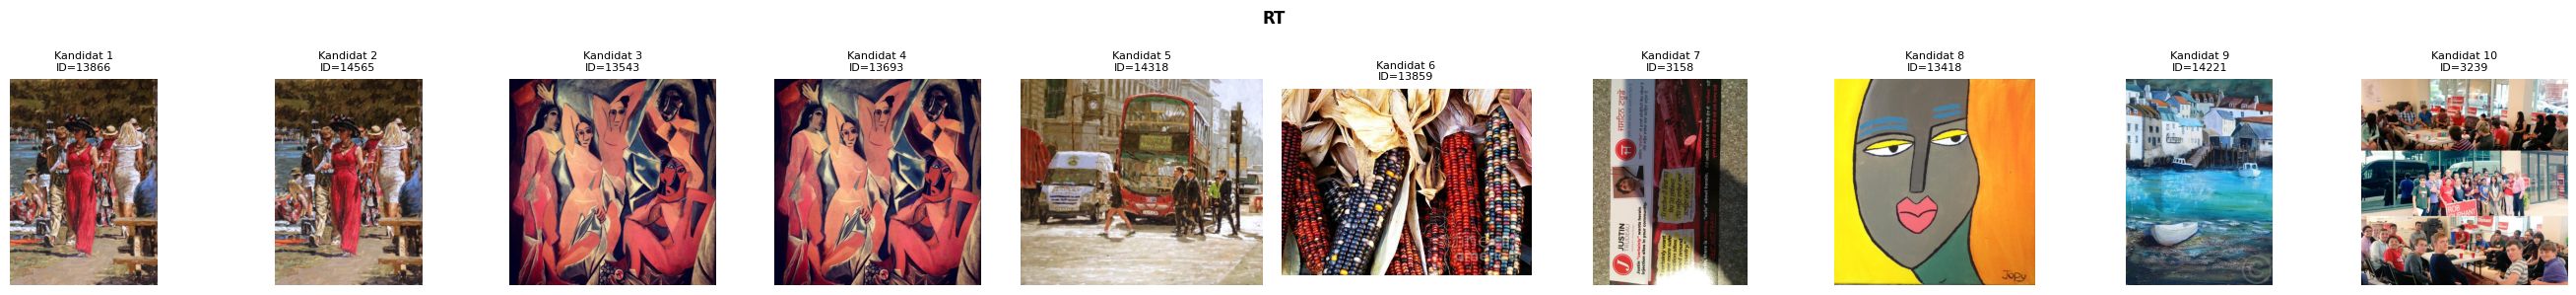

Kandidat 1 | ID=13866 | T pos/pos/pos | I pos/pos/pos | positive
    This for your eyes.. Beautiful work. #art #painting RT@tonykarpinski Henley Regatta oil painting
Kandidat 2 | ID=14565 | T pos/pos/pos | I pos/neu/pos | positive
    This for your eyes.. Beautiful work. #art #painting RT@tonykarpinski Henley Regatta oil painting
Kandidat 3 | ID=13543 | T pos/pos/pos | I pos/pos/neu | positive
    Yo, Picasso in da house, y'all! RT@MarkGKirshner Instagram #Picasso at MOMA #art #painting
Kandidat 4 | ID=13693 | T neu/pos/pos | I neu/pos/neu | positive
    Yo, Picasso in da house, y'all! RT@MarkGKirshner Instagram #Picasso at MOMA #art #painting
Kandidat 5 | ID=14318 | T pos/pos/pos | I neu/neu/pos | positive
    Beautiful! Hey, you see The Beatles? :) RT@beaconrangers: Nice! RT @rosequartz0518 MT @tonykarpinski #art
    #painting
Kandidat 6 | ID=13859 | T pos/neu/pos | I pos/neu/pos | positive
    Some mid-morning #art 4 yr eyes: RT@SMaureneLoft via @dtfpress NewArtwork4Sale! Indian Cor

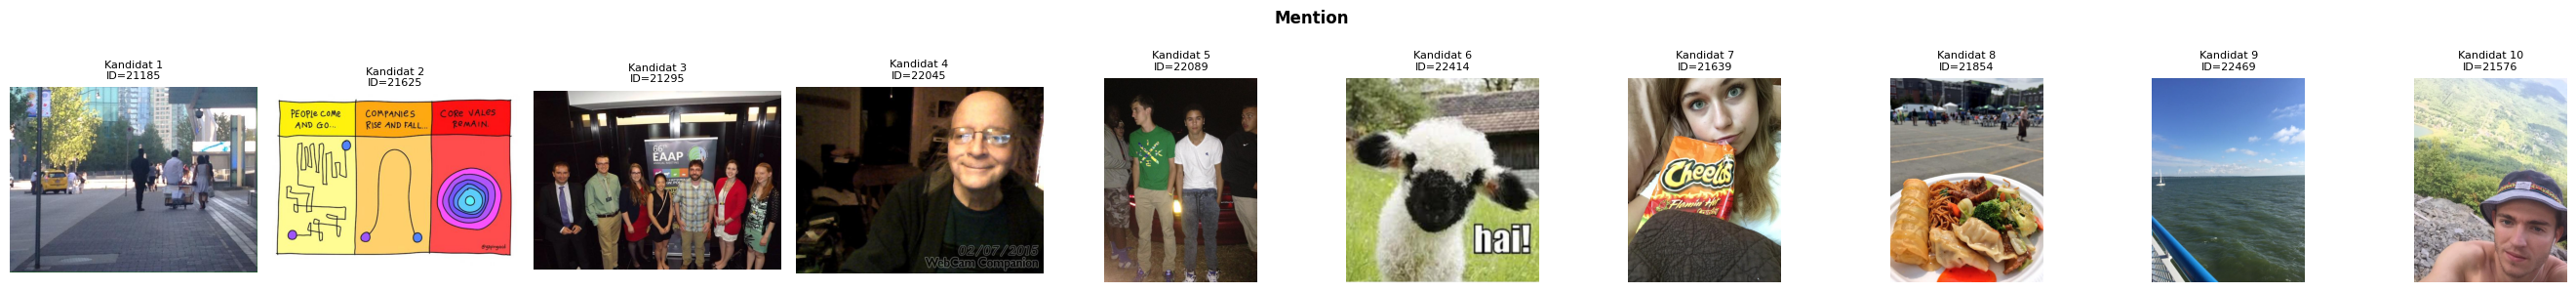

Kandidat 1 | ID=21185 | T neu/neu/neg | I neu/neu/neg | neutral
    @nickeagland But wait. Why are people in white heading away from Canada Place?
Kandidat 2 | ID=21625 | T pos/pos/neu | I neu/neu/neu | positive
    Yup, having lunch with @gapingvoid = awesome (his art, not the human lol)
Kandidat 3 | ID=21295 | T neu/pos/neu | I neu/pos/neu | neutral
    Dalhousie feed efficiency research group with the EAAP President in Warsaw, Poland @dalagriculture
    @EAAPofficial
Kandidat 4 | ID=22045 | T pos/pos/pos | I pos/pos/neg | positive
    @AvrilLavigne Love and admire you in all ways dearest Avril,your Benson William
    Heller.billheller72@yahoo.comzip14813
Kandidat 5 | ID=22089 | T pos/pos/neu | I pos/neu/neu | positive
    Shoutout to all my sons on their second day of school @LukeLaw24 @warren_lavette and silky
Kandidat 6 | ID=22414 | T pos/pos/pos | I pos/neu/pos | positive
    @MsJennie99 Good morning miss Jennie. I hope you find your smile. ?
Kandidat 7 | ID=21639 | T neu/neu/neg

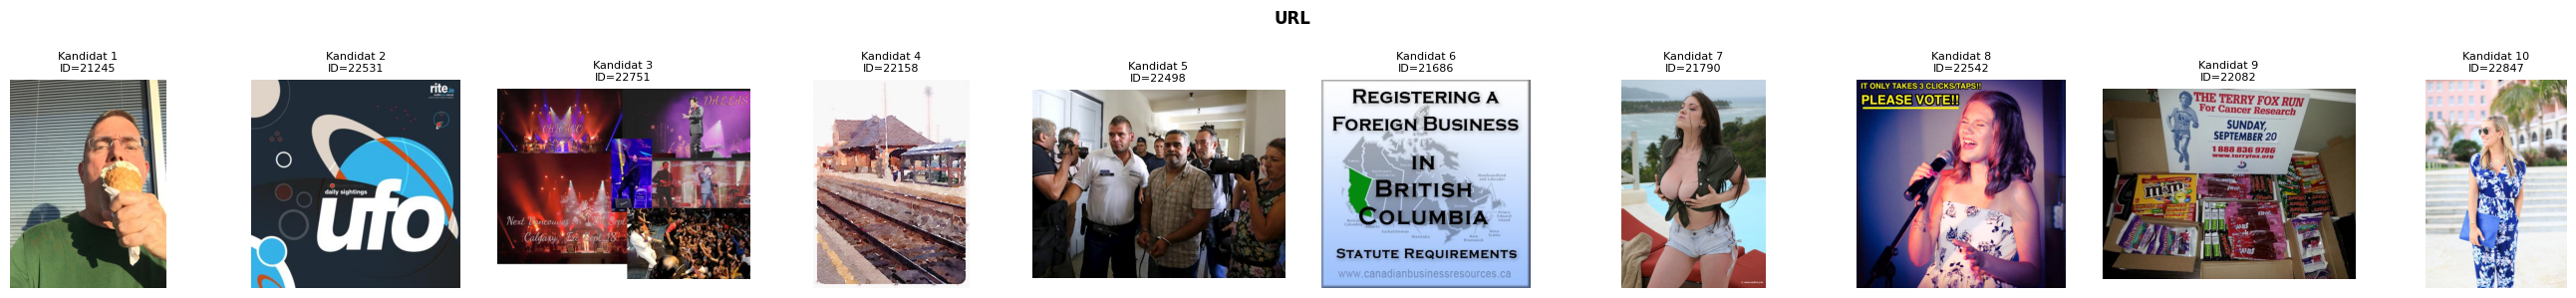

Kandidat 1 | ID=21245 | T pos/pos/pos | I pos/pos/pos | positive
    Love this place the best (@ Hewitt's Dairy Bar in Haldimand, Ontario) https://t.co/0RM9XN1rR6
Kandidat 2 | ID=22531 | T pos/neg/pos | I pos/neu/pos | positive
    Time Travel Rookie Error: Aiming at Days That Never Existed http://t.co/goOTSsokyJ
Kandidat 3 | ID=22751 | T pos/neu/pos | I neu/pos/pos | positive
    Next Vancouver on the 12th Sept and Calgary Sep 18 Get your tickets NOW - https://t.co/JKqmq1C8AD
Kandidat 4 | ID=22158 | T pos/pos/neu | I neu/neu/pos | positive
    It's Friday! Best wishes for today and have a great weekend (@ Brampton GO Station)
    https://t.co/G4zEhbOCf3
Kandidat 5 | ID=22498 | T neg/neu/neg | I neg/neu/neg | negative
    Three refugee children found critically ill in Austria http://t.co/KY6AzhMEjT
Kandidat 6 | ID=21686 | T pos/neu/neu | I neg/neu/neu | neutral
    WHAT ARE THE LAWS REQUIRING A COMPANY CONDUCTING BUSINESS IN BC TO BE OBLIGATED TO REGISTER
    http://t.co/xyUelzb1sF
Kan

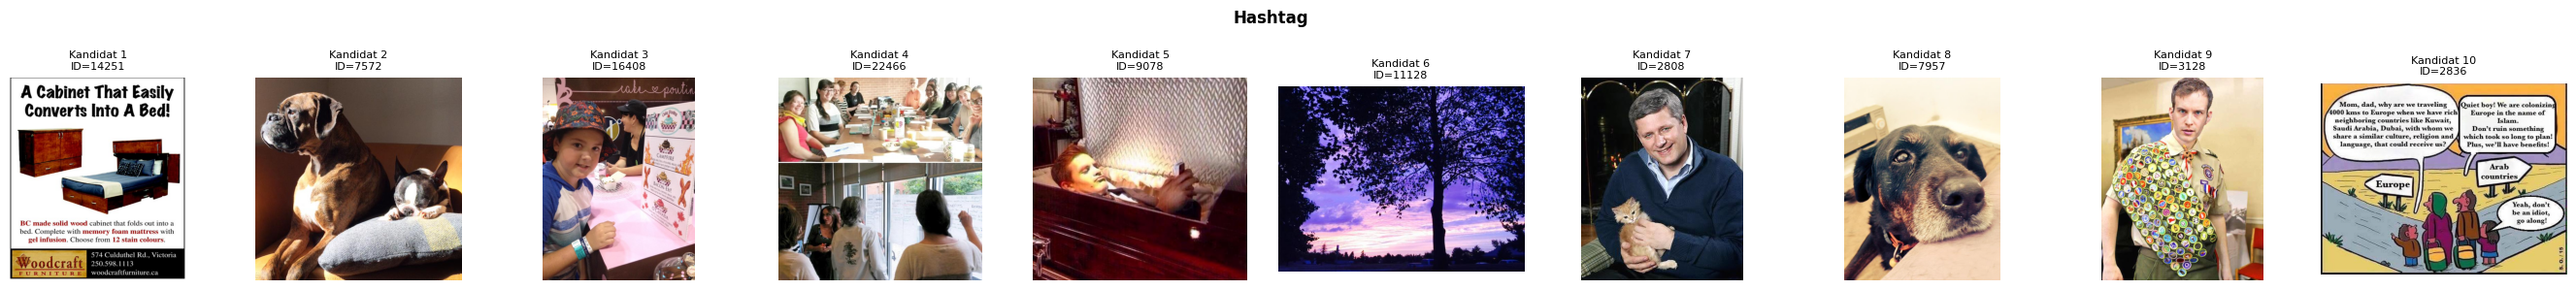

Kandidat 1 | ID=14251 | T neu/neu/neu | I neu/pos/neu | neutral
    CabinetBed available in #victoria #bc at Woodcraft Furniture #simplebutsmart #advertising #branding
    #furniture
Kandidat 2 | ID=7572 | T pos/neu/pos | I pos/pos/pos | positive
    Best friends Tia and Rocco enjoying a well deserved rest on #NationalDogDay
Kandidat 3 | ID=16408 | T neu/pos/neu | I neu/neu/neu | neutral
    Cake poutine is a winner at the Canadian National Exhibition! #CNE #Toronto
Kandidat 4 | ID=22466 | T neu/neu/neu | I neu/neu/neu | neutral
    Worker-member meeting this morning, nailing down some solid policies! #democraticworkplace #supportcoops
    #lovemycoop
Kandidat 5 | ID=9078 | T neu/pos/pos | I neu/pos/pos | positive
    When Michael's hair kills you but you still have to vote #ShesKindaHotVMA
Kandidat 6 | ID=11128 | T pos/pos/pos | I pos/pos/pos | positive
    Last night's sunset reminded me of #Fiji . #canada #travel #bc #lp
Kandidat 7 | ID=2808 | T neg/pos/pos | I neu/pos/pos | positiv

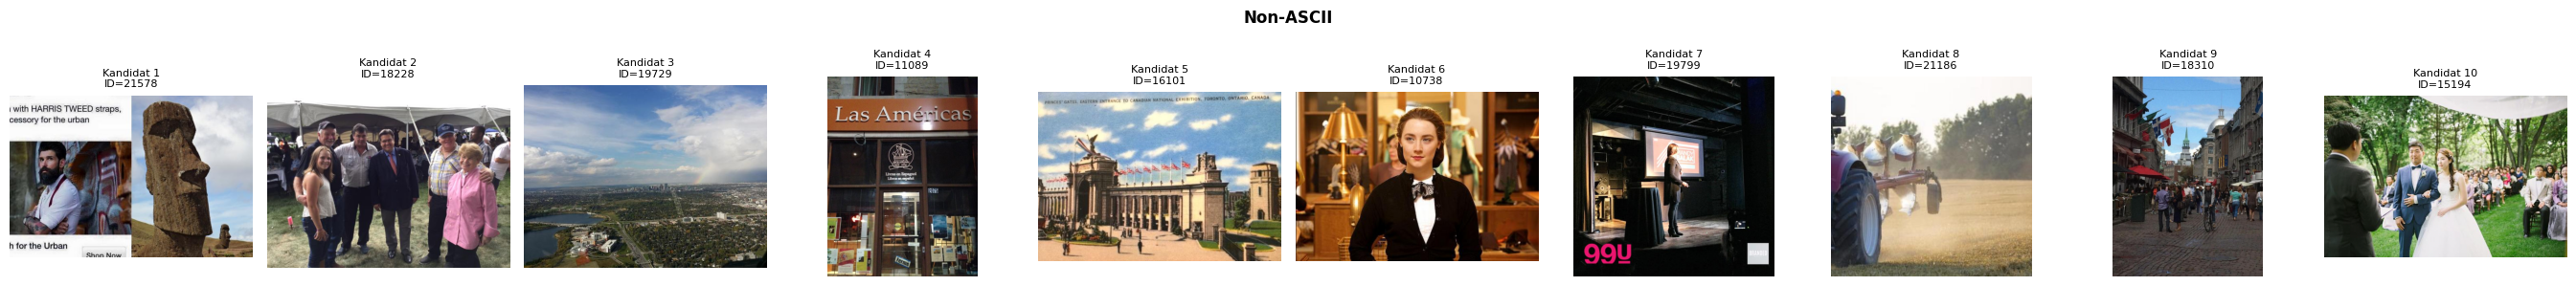

Kandidat 1 | ID=21578 | T neu/neu/pos | I neu/pos/pos | positive
    I think I’ve worked out where this fashion trend is heading
Kandidat 2 | ID=18228 | T neu/pos/neu | I neu/pos/pos | positive
    In #Montreal today for Soeur Angele's Fete Champetre with Mayor Denis Coté!
Kandidat 3 | ID=19729 | T neg/neu/neu | I neg/pos/pos | positive
    Rainbow in #yyc this afternoon! 11° right now. Frost advisory in effect overnight.
Kandidat 4 | ID=11089 | T neg/neu/neu | I pos/neu/pos | positive
    #español bookshop in #français speaking #Canada! #languages #culture #books
Kandidat 5 | ID=16101 | T pos/neu/pos | I neu/neu/pos | positive
    Ah, #summer…#PrincesGates #CNE #lastday #LabourDay, we're closed today... #postcard #vintage #Toronto
    #Bloordale
Kandidat 6 | ID=10738 | T neu/neu/pos | I pos/pos/pos | positive
    ICYMI the 2015 #VIFF #OpeningGala will be #Brooklyn – #EyeOnCanada
Kandidat 7 | ID=19799 | T pos/pos/neg | I pos/neu/neu | positive
    ‘The moment I said FUCK YES, my life c

In [26]:
# Kandidat per jenis noise teks
POOL_NOISE, CAND_NOISE = {}, {}
for name in NOISE_PATTERNS:
    POOL_NOISE[name] = set(df_final['ID'])
    CAND_NOISE[name] = pair_candidates(df_final['ID'], target_noise=name)

print('Keterangan. T = label 3 annotator untuk teks, I = label 3 annotator untuk gambar, lalu final_label.')
show_pairs(CAND_NOISE)

Sampel noise: {'RT': 13866, 'Mention': 21185, 'URL': 22498, 'Hashtag': 14251, 'Non-ASCII': 21578}


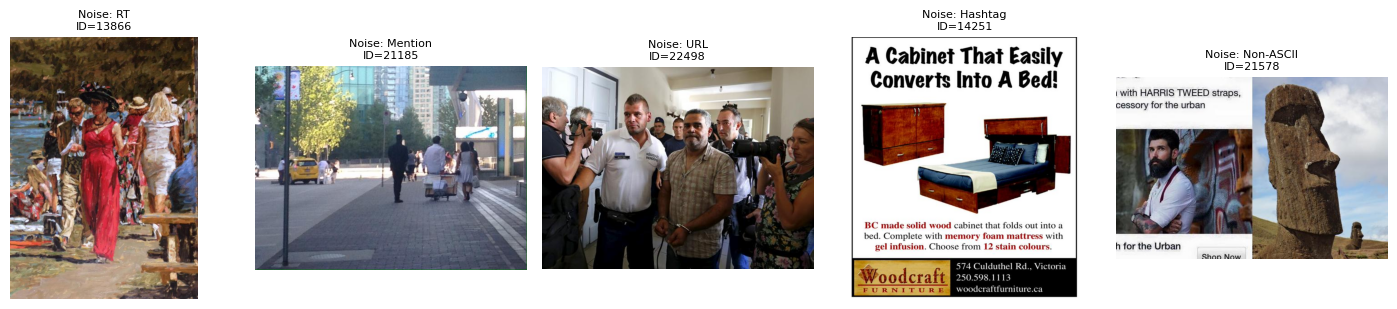

Noise RT | ID=13866 | T pos/pos/pos | I pos/pos/pos | positive
    This for your eyes.. Beautiful work. #art #painting RT@tonykarpinski Henley Regatta oil painting
Noise Mention | ID=21185 | T neu/neu/neg | I neu/neu/neg | neutral
    @nickeagland But wait. Why are people in white heading away from Canada Place?
Noise URL | ID=22498 | T neg/neu/neg | I neg/neu/neg | negative
    Three refugee children found critically ill in Austria http://t.co/KY6AzhMEjT
Noise Hashtag | ID=14251 | T neu/neu/neu | I neu/pos/neu | neutral
    CabinetBed available in #victoria #bc at Woodcraft Furniture #simplebutsmart #advertising #branding
    #furniture
Noise Non-ASCII | ID=21578 | T neu/neu/pos | I neu/pos/pos | positive
    I think I’ve worked out where this fashion trend is heading


In [27]:
# Isi ID pilihan dari gambar dan teks di atas. Kelompok yang dikosongkan otomatis memakai
# kandidat yang menghindari ID dan kelas final_label yang sudah terpakai.
# Contoh. PICK_NOISE = {'URL': 2502}
PICK_NOISE = {}   # kunci: 'RT', 'Mention', 'URL', 'Hashtag', 'Non-ASCII'

def check_picks(picks, pools):
    unknown = set(picks) - set(pools)
    if unknown:
        raise KeyError(f'Kunci tidak dikenal: {unknown}. Kunci valid: {list(pools)}')
    for key, id_ in picks.items():
        if id_ not in pools[key]:
            raise ValueError(f"ID {id_} tidak termasuk kelompok '{key}'")
        if not (text_check(id_)[0] and image_check(id_)):
            print(f"Catatan: ID {id_} ('{key}') tidak lolos filter teks/gambar, tetap dipakai sesuai pilihan Anda.")

check_picks(PICK_NOISE, POOL_NOISE)
if len(set(PICK_NOISE.values())) < len(PICK_NOISE):
    raise ValueError('PICK_NOISE berisi ID yang sama untuk lebih dari satu jenis noise.')

# Pilihan manual dulu, lalu isi sisanya dengan ID unik dan kelas final_label beragam
chosen_noise = dict(PICK_NOISE)
used_ids = set(chosen_noise.values())
used_cls = {meta.loc[i, 'final_label'] for i in used_ids}
for name in POOL_NOISE:
    if name in chosen_noise:
        continue
    ids = [r[2] for r in CAND_NOISE[name] if r[2] not in used_ids]
    if not ids:
        print(f"Peringatan. Tidak ada kandidat untuk noise '{name}', dilewati.")
        continue
    fresh = [i for i in ids if meta.loc[i, 'final_label'] not in used_cls]
    chosen_noise[name] = (fresh or ids)[0]
    used_ids.add(chosen_noise[name]); used_cls.add(meta.loc[chosen_noise[name], 'final_label'])
chosen_noise = {n: chosen_noise[n] for n in NOISE_PATTERNS if n in chosen_noise}

print('Sampel noise:', chosen_noise)

fig, axes = plt.subplots(1, len(chosen_noise), figsize=(2.9 * len(chosen_noise), 3.2), squeeze=False)
for ax, (name, id_) in zip(axes[0], chosen_noise.items()):
    draw_pair(ax, id_, f'Noise: {name}')
plt.tight_layout(); plt.show()
for name, id_ in chosen_noise.items():
    print_pair_text(f'Noise {name}', id_)

## 24. Contoh Preprocessing Teks

Preprocessing teks terdiri dari dua tahap yang sama dengan notebook pelatihan ALBERT.
1. **Pembersihan teks.** Fungsi `clean_text` menghapus penanda RT dan mention, menghapus URL, mengubah hashtag menjadi kata biasa, membuang karakter non-ASCII, lalu merapikan spasi.
2. **Tokenisasi.** `AlbertTokenizer` dari `albert-base-v2` dengan `max_length=128`, padding, dan truncation. Tokenizer memakai SentencePiece. Token diawali `[CLS]` dan diakhiri `[SEP]`, dan tanda `▁` menandai awal kata.

Tokenizer diunduh dari Hugging Face, sehingga akses internet pada Kaggle harus aktif.

In [28]:
import re
import textwrap
from transformers import AlbertTokenizer

MAX_SEQ_LEN = 128
tokenizer = AlbertTokenizer.from_pretrained('albert-base-v2')

def clean_text(text):
    # Sama dengan fungsi pada notebook pelatihan ALBERT
    text = re.sub(r'\bRT\b\s*@\w+:?\s*', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

# Sampel noise dipilih pada Section 23 (chosen_noise)
chosen = {name: (id_, read_text(id_)) for name, id_ in chosen_noise.items()}

def show(label, text, width=110):
    print(textwrap.fill(f'{label:<12}: {text}', width=width, subsequent_indent=' ' * 14))

for no, (name, (id_, raw)) in enumerate(chosen.items(), start=1):
    cleaned = clean_text(raw)
    enc     = tokenizer(cleaned, max_length=MAX_SEQ_LEN, padding='max_length', truncation=True)
    n_tok   = sum(enc['attention_mask'])
    ids     = enc['input_ids'][:n_tok]
    tokens  = tokenizer.convert_ids_to_tokens(ids)

    print('=' * 110)
    print(f"Sampel {no} | ID={id_} | noise: {name}")
    print('=' * 110)
    show('Teks asli',   raw.replace('\n', ' '))
    show('Teks bersih', cleaned)
    show('Token',       ' '.join(tokens))
    show('Token ID',    ' '.join(map(str, ids)))
    print(f"Jumlah token: {n_tok} dari {MAX_SEQ_LEN} (padding {MAX_SEQ_LEN - n_tok})\n")

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

Sampel 1 | ID=13866 | noise: RT
Teks asli   : This for your eyes.. Beautiful work. #art #painting RT@tonykarpinski Henley Regatta oil painting
Teks bersih : This for your eyes.. Beautiful work. art painting Henley Regatta oil painting
Token       : [CLS] ▁this ▁for ▁your ▁eyes . . ▁beautiful ▁work . ▁art ▁painting ▁henley ▁regatta ▁oil
              ▁painting [SEP]
Token ID    : 2 48 26 154 194 9 9 1632 170 9 415 2469 23223 26491 1585 2469 3
Jumlah token: 17 dari 128 (padding 111)

Sampel 2 | ID=21185 | noise: Mention
Teks asli   : @nickeagland But wait. Why are people in white heading away from Canada Place?
Teks bersih : But wait. Why are people in white heading away from Canada Place?
Token       : [CLS] ▁but ▁wait . ▁why ▁are ▁people ▁in ▁white ▁heading ▁away ▁from ▁canada ▁place ? [SEP]
Token ID    : 2 47 1760 9 483 50 148 19 359 4582 229 37 836 209 60 3
Jumlah token: 16 dari 128 (padding 112)

Sampel 3 | ID=22498 | noise: URL
Teks asli   : Three refugee children found critically 

## 25. Contoh Preprocessing Gambar

Preprocessing gambar terdiri dari tiga tahap yang sama dengan notebook pelatihan. Gambar berasal dari tweet yang sama dengan sampel teks pada Section 24.
1. **Resize.** Ukuran diubah menjadi 224x224 untuk MobileNetV3-Small dan 256x256 untuk MobileViT-XXS.
2. **ToTensor.** Nilai piksel diubah ke skala 0 sampai 1.
3. **Normalisasi.** Setiap kanal dinormalisasi dengan mean `[0.485, 0.456, 0.406]` dan standar deviasi `[0.229, 0.224, 0.225]`, yaitu statistik ImageNet yang sesuai dengan bobot pralatih kedua model.

Setiap tahap disimpan sebagai berkas PNG pada folder `output_mvsa_multiple/preprocessing_gambar` dengan pola nama `ID<id>_<tahap>.png`. Berkas `asli` memuat gambar ukuran asli. Berkas `resize224` dan `normalisasi224` untuk MobileNetV3-Small, serta `resize256` dan `normalisasi256` untuk MobileViT-XXS.

Hasil normalisasi memuat nilai negatif sehingga pada berkas PNG diskalakan ulang ke rentang 0 sampai 1 hanya untuk tampilan. Nilai sebenarnya ada pada tabel.

In [29]:
import numpy as np
import torch
import torchvision.transforms as T

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
MODELS = {'MobileNetV3-Small': 224, 'MobileViT-XXS': 256}

# OUTPUT_DIR didefinisikan pada konfigurasi di awal notebook
PREP_DIR   = os.path.join(OUTPUT_DIR, 'preprocessing_gambar')
import shutil
shutil.rmtree(PREP_DIR, ignore_errors=True)  # buang file sampel lama bila notebook dijalankan ulang
os.makedirs(PREP_DIR, exist_ok=True)

to_tensor = T.ToTensor()
normalize = T.Normalize(IMAGENET_MEAN, IMAGENET_STD)

# Gambar dari tweet yang sama dengan sampel teks Section 24 (hasil seleksi Section 23)
img_samples = [df_final[df_final['ID'] == id_].iloc[0] for id_ in chosen_noise.values()]

def rgb_mean(t):
    return [round(float(v), 3) for v in t.mean(dim=(1, 2))]

def tensor_to_pil(t):
    # Tensor CHW skala 0-1 menjadi gambar PIL
    arr = (t.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
    return Image.fromarray(arr)

stats = []
for row in img_samples:
    id_ = row['ID']
    with Image.open(os.path.join(DATA_DIR, f'{id_}.jpg')) as im:
        img = im.convert('RGB')
    w, h = img.size

    img.save(os.path.join(PREP_DIR, f'ID{id_}_asli.png'))
    saved = [f'ID{id_}_asli.png']

    for model_name, size in MODELS.items():
        resized   = T.Resize((size, size))(img)
        before    = to_tensor(resized)
        after     = normalize(before)
        after_vis = (after - after.min()) / (after.max() - after.min())  # hanya untuk tampilan

        resized.save(os.path.join(PREP_DIR, f'ID{id_}_resize{size}.png'))
        tensor_to_pil(after_vis).save(os.path.join(PREP_DIR, f'ID{id_}_normalisasi{size}.png'))
        saved += [f'ID{id_}_resize{size}.png', f'ID{id_}_normalisasi{size}.png']

        stats.append({
            'ID'                : id_,
            'Model'             : model_name,
            'Ukuran asli'       : f'{w}x{h}',
            'Shape tensor'      : tuple(after.shape),
            'Rentang ToTensor'  : f'{before.min():.2f} s.d. {before.max():.2f}',
            'Rentang Normalize' : f'{after.min():.2f} s.d. {after.max():.2f}',
            'Mean RGB sebelum'  : rgb_mean(before),
            'Mean RGB sesudah'  : rgb_mean(after),
        })

    print(f"ID={id_} ({row['final_label']}) -> {', '.join(saved)}")

print(f"\nFile disimpan di: {PREP_DIR} ({len(os.listdir(PREP_DIR))} file)")

with pd.option_context('display.max_colwidth', None, 'display.width', 250):
    display(pd.DataFrame(stats))

ID=13866 (positive) -> ID13866_asli.png, ID13866_resize224.png, ID13866_normalisasi224.png, ID13866_resize256.png, ID13866_normalisasi256.png
ID=21185 (neutral) -> ID21185_asli.png, ID21185_resize224.png, ID21185_normalisasi224.png, ID21185_resize256.png, ID21185_normalisasi256.png
ID=22498 (negative) -> ID22498_asli.png, ID22498_resize224.png, ID22498_normalisasi224.png, ID22498_resize256.png, ID22498_normalisasi256.png
ID=14251 (neutral) -> ID14251_asli.png, ID14251_resize224.png, ID14251_normalisasi224.png, ID14251_resize256.png, ID14251_normalisasi256.png
ID=21578 (positive) -> ID21578_asli.png, ID21578_resize224.png, ID21578_normalisasi224.png, ID21578_resize256.png, ID21578_normalisasi256.png

File disimpan di: output_mvsa_multiple/preprocessing_gambar (25 file)


,ID,Model,Ukuran asli,Shape tensor,Rentang ToTensor,Rentang Normalize,Mean RGB sebelum,Mean RGB sesudah
0,13866,MobileNetV3-Small,600x839,"(3, 224, 224)",0.02 s.d. 1.00,-2.00 s.d. 2.64,"[0.477, 0.359, 0.311]","[-0.034, -0.431, -0.423]"
1,13866,MobileViT-XXS,600x839,"(3, 256, 256)",0.01 s.d. 1.00,-1.98 s.d. 2.64,"[0.477, 0.359, 0.311]","[-0.034, -0.431, -0.423]"
2,21185,MobileNetV3-Small,599x449,"(3, 224, 224)",0.07 s.d. 1.00,-1.83 s.d. 2.64,"[0.46, 0.488, 0.513]","[-0.109, 0.141, 0.475]"
3,21185,MobileViT-XXS,599x449,"(3, 256, 256)",0.07 s.d. 1.00,-1.83 s.d. 2.64,"[0.46, 0.488, 0.513]","[-0.109, 0.141, 0.474]"
4,22498,MobileNetV3-Small,600x446,"(3, 224, 224)",0.00 s.d. 1.00,-2.12 s.d. 2.64,"[0.388, 0.353, 0.332]","[-0.424, -0.461, -0.327]"
5,22498,MobileViT-XXS,600x446,"(3, 256, 256)",0.00 s.d. 1.00,-2.12 s.d. 2.64,"[0.388, 0.353, 0.332]","[-0.424, -0.461, -0.327]"
6,14251,MobileNetV3-Small,600x691,"(3, 224, 224)",0.00 s.d. 1.00,-2.12 s.d. 2.64,"[0.679, 0.628, 0.606]","[0.846, 0.769, 0.887]"
7,14251,MobileViT-XXS,600x691,"(3, 256, 256)",0.00 s.d. 1.00,-2.12 s.d. 2.64,"[0.679, 0.628, 0.606]","[0.847, 0.77, 0.888]"
8,21578,MobileNetV3-Small,599x400,"(3, 224, 224)",0.00 s.d. 1.00,-2.12 s.d. 2.64,"[0.55, 0.536, 0.536]","[0.286, 0.357, 0.579]"
9,21578,MobileViT-XXS,599x400,"(3, 256, 256)",0.00 s.d. 1.00,-2.12 s.d. 2.64,"[0.55, 0.536, 0.536]","[0.286, 0.357, 0.579]"


## 26. Contoh Augmentasi Gambar

Augmentasi hanya diterapkan pada data latih dengan tujuan menambah variasi visual dan mengurangi risiko overfitting. Data validasi tidak diaugmentasi. Parameter sama dengan notebook pelatihan.
- `T.RandomHorizontalFlip(p=0.5)`
- `T.RandomRotation(10)`
- `T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02)`

Parameter dibuat ringan agar makna visual gambar tidak berubah. Contoh memakai gambar yang sama dengan Section 25 setelah resize 224x224. Hasil disimpan pada folder `output_mvsa_multiple/augmentasi_gambar`.
- `sebelum_aug`. Gambar sebelum augmentasi.
- `flip`. Hanya flip. Berkas ini menampilkan kasus saat flip terjadi, karena dengan `p=0.5` separuh gambar tidak berubah.
- `rotasi`. Hanya rotasi dengan sudut antara -10 dan 10 derajat.
- `colorjitter`. Hanya color jitter.
- `gabungan`. Urutan pada pelatihan, yaitu flip, rotasi, lalu color jitter.

Nilai acak yang terpilih dicatat pada tabel.

In [30]:
class LoggedRotation(T.RandomRotation):
    # Sama dengan T.RandomRotation, hanya mencatat sudut yang terpilih
    def get_params(self, degrees):
        self.last_angle = T.RandomRotation.get_params(degrees)
        return self.last_angle

class LoggedColorJitter(T.ColorJitter):
    # Sama dengan T.ColorJitter, hanya mencatat faktor yang terpilih
    def get_params(self, brightness, contrast, saturation, hue):
        params = T.ColorJitter.get_params(brightness, contrast, saturation, hue)
        self.last_factors = params[1:]  # brightness, contrast, saturation, hue
        return params

AUG_DIR = os.path.join(OUTPUT_DIR, 'augmentasi_gambar')
import shutil
shutil.rmtree(AUG_DIR, ignore_errors=True)  # buang file sampel lama bila notebook dijalankan ulang
os.makedirs(AUG_DIR, exist_ok=True)

flip_tf   = T.RandomHorizontalFlip(p=0.5)
rot_tf    = LoggedRotation(10)
jit_tf    = LoggedColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02)
resize_tf = T.Resize((224, 224))

torch.manual_seed(42)

def jitter_text(f):
    b, c, s, h = f
    return f'b={b:.2f} c={c:.2f} s={s:.2f} h={h:+.3f}'

aug_rows = []
for row in img_samples:
    id_ = row['ID']
    with Image.open(os.path.join(DATA_DIR, f'{id_}.jpg')) as im:
        base = resize_tf(im.convert('RGB'))

    # Flip: ulangi sampai flip terjadi (objek yang sama dikembalikan bila tidak flip)
    for _ in range(50):
        flipped = flip_tf(base)
        if flipped is not base:
            break

    rotated  = rot_tf(base)
    angle    = rot_tf.last_angle
    jittered = jit_tf(base)
    factors  = jit_tf.last_factors

    # Gabungan: urutan sama dengan pipeline pelatihan
    combo     = flip_tf(base)
    did_flip  = combo is not base
    combo     = rot_tf(combo)
    angle_c   = rot_tf.last_angle
    combo     = jit_tf(combo)
    factors_c = jit_tf.last_factors

    results = {'sebelum_aug': base, 'flip': flipped, 'rotasi': rotated,
               'colorjitter': jittered, 'gabungan': combo}
    for name, im_ in results.items():
        im_.save(os.path.join(AUG_DIR, f'ID{id_}_{name}.png'))

    aug_rows.append({
        'ID'                : id_,
        'Rotasi (derajat)'  : round(angle, 1),
        'ColorJitter'       : jitter_text(factors),
        'Gabungan: flip'    : 'ya' if did_flip else 'tidak',
        'Gabungan: rotasi'  : round(angle_c, 1),
        'Gabungan: jitter'  : jitter_text(factors_c),
    })

print(f"File disimpan di: {AUG_DIR} ({len(os.listdir(AUG_DIR))} file)\n")

with pd.option_context('display.max_colwidth', None, 'display.width', 250):
    display(pd.DataFrame(aug_rows))

File disimpan di: output_mvsa_multiple/augmentasi_gambar (25 file)



,ID,Rotasi (derajat),ColorJitter,Gabungan: flip,Gabungan: rotasi,Gabungan: jitter
0,13866,9.2,b=1.06 c=1.09 s=0.93 h=+0.017,tidak,7.4,b=1.08 c=1.01 s=0.95 h=+0.005
1,21185,-1.2,b=0.95 c=0.97 s=0.94 h=+0.002,ya,9.0,b=0.97 c=1.06 s=1.02 h=+0.016
2,22498,2.7,b=1.06 c=0.96 s=1.06 h=+0.004,tidak,-6.1,b=1.08 c=1.03 s=1.04 h=+0.006
3,14251,7.8,b=1.03 c=0.97 s=1.03 h=-0.004,tidak,-5.9,b=1.03 c=1.10 s=0.92 h=-0.020
4,21578,-6.7,b=0.95 c=0.93 s=1.05 h=-0.008,tidak,-2.4,b=1.03 c=1.02 s=0.97 h=+0.012


# Bagian V. Ekspor Hasil

## 27. Pengemasan Output

Seluruh keluaran dikemas dalam satu berkas ZIP, yaitu `labelResult_cleaned.csv`, grafik, gambar preprocessing, dan gambar augmentasi. Di Kaggle, berkas ZIP tersedia pada tab Output.

## Referensi

- Fleiss, J. L. (1971). Measuring nominal scale agreement among many raters. *Psychological Bulletin*, 76(5), 378-382.
- Landis, J. R., dan Koch, G. G. (1977). The measurement of observer agreement for categorical data. *Biometrics*, 33(1), 159-174.
- Niu, T., Zhu, S., Pang, L., dan El Saddik, A. (2016). Sentiment analysis on multi-view social data. *MultiMedia Modeling (MMM)*, 15-27.
- Xu, N., dan Mao, W. (2017). MultiSentiNet: A deep semantic network for multimodal sentiment analysis. *Proceedings of CIKM*, 2399-2402.

In [31]:
import shutil
from IPython.display import FileLink

# Seluruh output berada pada OUTPUT_DIR. Folder preprocessing_gambar dan augmentasi_gambar
# terisi pada Section 25 dan 26, grafik terisi sepanjang notebook.
zip_path = shutil.make_archive(OUTPUT_DIR, 'zip', OUTPUT_DIR)

for sub in ('grafik', 'preprocessing_gambar', 'augmentasi_gambar'):
    path = os.path.join(OUTPUT_DIR, sub)
    n = len(os.listdir(path)) if os.path.isdir(path) else 0
    print(f"{sub:<22}: {n} file")
print(f"labelResult_cleaned.csv : {'ada' if os.path.exists(os.path.join(OUTPUT_DIR, 'labelResult_cleaned.csv')) else 'tidak ada'}")
print(f"ZIP                    : {zip_path}")
FileLink(zip_path)

grafik                : 8 file
preprocessing_gambar  : 25 file
augmentasi_gambar     : 25 file
labelResult_cleaned.csv : ada
ZIP                    : /kaggle/working/output_mvsa_multiple.zip


/kaggle/working/output_mvsa_multiple.zip